# Process the sqY2H data

This is the main PPI profiling assay. This script loads the raw scores and processes them into consensus scores. Throughout the script, "ad" means "activation domain" and "db" means "DNA binding domain" of a transcription factor. A protein is fused to each of these; if the two proteins interact, then the TF is able to up-regulate the expression of a gene that allows the yeast to survive on the media. Thus, the yeast growth score is correlated to the protein-protein interaction strength.

In [1]:
import pandas as pd 
import polars as pl
import numpy as np
from striprtf.striprtf import rtf_to_text
import re

In [2]:
inputs_dir = "../1_inputs/sqY2H"
outputs_dir = "../3_outputs"
meta_outputs = "../../../1_allele_collection/3_outputs"
meta_inputs = "../../../1_allele_collection/1_inputs"

In [3]:
# read in a list of ORF IDs and swim seq validation results
raw_scores = pd.read_table(f"{inputs_dir}/VarChAMP_1percent_Y2H_scores_v2.tsv")


In [4]:
large_plates = raw_scores["large_plate_name"].unique()
raw_scores = raw_scores[[
    "growth_score_id", "scoring_pla", "scoring_pos", "manual_score_growth"
]]
raw_scores[['retest_batch', 'condition', 'retest_pla']] = raw_scores['scoring_pla'].str.extract(r"([A-Z0-9]+)(r\d+)_0*(\d+)")
raw_scores['retest_pla'] = raw_scores['retest_pla'].astype(int)

In [5]:
# Control positions
ctrl_wells = ['A01', 'A02', 'B01', 'B02',
              'C01', 'C02', 'D01', 'D02',
              'E01', 'E02', 'F01', 'F02',
              'G01', 'G02', 'H01', 'H02',
              'I01', 'I02', 'J01', 'J02',
              'K01', 'K02', 'L01', 'L02']

# Get first plates
first_plates = np.unique([x.split("_")[1] for x in large_plates])
first_plates = first_plates.astype(int).tolist()

# Add column indicating if its a media control well
raw_scores['media_control'] = raw_scores['retest_pla'].isin(first_plates) & raw_scores['scoring_pos'].isin(ctrl_wells)

In [6]:
# Make the scores match an allele to the 96 wells of the source plate 
allele_map = pd.read_csv(f"{inputs_dir}/cp_files/mapping_y2h.csv").drop(columns=['ad_symbol', 'db_symbol'])

# create dictionary mapping 96 well position to 384 well position
with open(f"{inputs_dir}/mapping_384_to_96.rtf", "r") as f:
    rtf_content = f.read()

plain_text = rtf_to_text(rtf_content)
match = re.search(r"mapping_384_to_96_d\s*=\s*({.*})", plain_text, re.DOTALL)
dict_str = match.group(1)
dict_str = dict_str.replace("\n", "").replace("\r", "")
map_384_96 = eval(dict_str)
map_df = pd.DataFrame(list(map_384_96.items()), columns=['scoring_pos', 'retest_pos'])

# Map the 96-pos to 384-pos
allele_map = allele_map.merge(map_df, on="retest_pos")
allele_map['retest_pla'] = allele_map['retest_pla'].astype(int)

In [7]:
condition_df = pd.DataFrame({
    "condition":  ["r07", "r08", "r09", "r10", "r11", "r12", "r13", "r14", "r15", "r16","r17", "r18"],
    "condition_name": ["LW", "LWA", "LWH1", "LWH10", "LWH25", "LWAH1", "LW", "LWA", "LWH1", "LWH10", "LWH25", "LWAH1"]
})

In [8]:
# add orf ids to scores
scores = raw_scores.merge(allele_map, on=["scoring_pos", "retest_batch", "retest_pla"], how="left")
scores['db_orf_id'] = scores['db_orf_id'].astype(str)
scores['db_mut_id'] = scores['db_mut_id'].astype(str)
scores['ad_orf_id'] = scores['ad_orf_id'].astype(str)
scores['ad_mut_id'] = scores['ad_mut_id'].astype(str)


In [9]:

# give media controls their own IDs
mask = scores['media_control'] == True
scores.loc[mask, 'db_orf_id'] = (
    scores.loc[mask, 'retest_pos'].astype(str) + '_' + scores.loc[mask, 'retest_pla'].astype(str)
)
scores.loc[mask, 'ad_orf_id'] = (
    scores.loc[mask, 'retest_pos'].astype(str) + '_' + scores.loc[mask, 'retest_pla'].astype(str)
)

# Filter out r01-r06 and convert to other condition names
exclude_list = ["r01", "r02", "r03", "r04", "r05", "r06"]
scores = scores[~scores['condition'].isin(exclude_list)]

# get only plates from relevant batches
scores = scores[scores.standard_batch.isin(["VUSAPWT1B1","VUSAPWT1B2","VUSAPWT2B1","VUSAPWT6B1"])]


In [10]:
# both db_orf_id and ad_orf_id must have values (otherwise they are empty wells)
scores = scores[
    (~scores.db_orf_id.isin(['nan', 'None'])) &
    (~scores.ad_orf_id.isin(['nan', 'None']))
]

# add named condition column
scores = scores.merge(condition_df, on="condition")

# write out file
scores.to_csv(f"{outputs_dir}/sqY2H/1_raw_individual_scores.csv", index=False)

In [11]:
scores
scores[
    (scores.ad_orf_id == '12626.0') &
    (scores.db_orf_id == '9905.0') &
    # (scores.db_mut_id == 215290)
    (scores.condition_name == "LW")
    ]

,growth_score_id,scoring_pla,scoring_pos,manual_score_growth,retest_batch,condition,retest_pla,media_control,retest_id,ad_orf_id,...,db_orf_id,db_mut_id,retest_pos,standard_batch,assay_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,condition_name
234082,NaN,VUSAPWT1B2r07_022,C01,4.0,VUSAPWT1B2,r07,22,False,63843.0,12626.0,...,9905.0,216950.0,B01,VUSAPWT1B2,1.0,VUSMutY8Dh028,C07,CEGSint_Y8A_2,E02,LW
234083,NaN,VUSAPWT1B2r07_022,C02,4.0,VUSAPWT1B2,r07,22,False,63843.0,12626.0,...,9905.0,216950.0,B01,VUSAPWT1B2,1.0,VUSMutY8Dh028,C07,CEGSint_Y8A_2,E02,LW
234106,NaN,VUSAPWT1B2r07_022,D01,4.0,VUSAPWT1B2,r07,22,False,63843.0,12626.0,...,9905.0,216950.0,B01,VUSAPWT1B2,1.0,VUSMutY8Dh028,C07,CEGSint_Y8A_2,E02,LW
234107,NaN,VUSAPWT1B2r07_022,D02,4.0,VUSAPWT1B2,r07,22,False,63843.0,12626.0,...,9905.0,216950.0,B01,VUSAPWT1B2,1.0,VUSMutY8Dh028,C07,CEGSint_Y8A_2,E02,LW
234146,NaN,VUSAPWT1B2r07_022,E17,4.0,VUSAPWT1B2,r07,22,False,63907.0,12626.0,...,9905.0,216952.0,C09,VUSAPWT1B2,1.0,VUSMutY8Dh028,B09,CEGSint_Y8A_2,E02,LW
234147,NaN,VUSAPWT1B2r07_022,E18,4.0,VUSAPWT1B2,r07,22,False,63907.0,12626.0,...,9905.0,216952.0,C09,VUSAPWT1B2,1.0,VUSMutY8Dh028,B09,CEGSint_Y8A_2,E02,LW
234170,NaN,VUSAPWT1B2r07_022,F17,4.0,VUSAPWT1B2,r07,22,False,63907.0,12626.0,...,9905.0,216952.0,C09,VUSAPWT1B2,1.0,VUSMutY8Dh028,B09,CEGSint_Y8A_2,E02,LW
234171,NaN,VUSAPWT1B2r07_022,F18,4.0,VUSAPWT1B2,r07,22,False,63907.0,12626.0,...,9905.0,216952.0,C09,VUSAPWT1B2,1.0,VUSMutY8Dh028,B09,CEGSint_Y8A_2,E02,LW
241216,NaN,VUSAPWT1B2r07_002,I11,NaN,VUSAPWT1B2,r07,2,False,62045.0,12626.0,...,9905.0,0.0,E06,VUSAPWT1B2,1.0,DisWTY8Dh01,D06,CEGSint_Y8A_2,E02,LW
241217,NaN,VUSAPWT1B2r07_002,I12,NaN,VUSAPWT1B2,r07,2,False,62045.0,12626.0,...,9905.0,0.0,E06,VUSAPWT1B2,1.0,DisWTY8Dh01,D06,CEGSint_Y8A_2,E02,LW


In [12]:

# Calculate the most frequent score (consensus_score_list)
scores = pl.DataFrame(scores)
consensus_scores = scores.group_by(['ad_orf_id', 'ad_mut_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch', 'media_control']).agg(
    pl.col("manual_score_growth").mode().alias("consensus_score_list")
)


# Determine whether there was a tie for the most frequent score
consensus_scores = consensus_scores.with_columns(
    pl.col("consensus_score_list").list.len().alias("num_most_freq")
)

# Easy cases - clear most frequent (num_most_freq == 1) or clear disagreement (num_most_freq > 2)
consensus_easy = consensus_scores.filter(pl.col("num_most_freq") != 2)
consensus_easy = consensus_easy.with_columns(
    pl.when(pl.col("num_most_freq") == 1)
      .then(pl.col("consensus_score_list").list.first())
      .when(pl.col("num_most_freq") > 2)
      .then(pl.lit(99999))
      .otherwise(None)
      .alias("consensus_score")
)

# Hard cases - two scores were most frequent. Rules:
# If they are consecutive (score_diff == 1), then take the maximum score
# If they aren't, mark as failure (99999)
# If one value is NaN, use the other value
consensus_hard = consensus_scores.filter(pl.col("num_most_freq") == 2)
consensus_hard = consensus_hard.with_columns(
    (pl.col("consensus_score_list").list.get(0) - pl.col("consensus_score_list").list.get(1))
    .abs()
    .alias("score_diff")
)
consensus_hard = consensus_hard.with_columns(
    pl.when(pl.col("score_diff") > 1)
      .then(pl.lit(99999))
      .when(pl.col("score_diff").is_null())
      .then(
          pl.col("consensus_score_list")
            .list.eval(pl.element().drop_nulls())
            .list.first()
      )
      .when(pl.col("score_diff") == 1)
      .then(
          pl.col("consensus_score_list")
            .list.eval(pl.element().max())
            .list.first()
      )
      .otherwise(None)
      .alias("consensus_score")
).drop("score_diff")

# Concatenate together
consensus_scores = pl.concat([consensus_easy, consensus_hard]).drop([
    "consensus_score_list", "num_most_freq"
])

In [13]:
# map ad_orf_id to ad_symbol

mapping_file = pd.read_csv(f"{inputs_dir}/cp_files/mapping_y2h.csv")
mapping_file.dropna(subset=['ad_orf_id'], inplace=True)
mapping_dict = mapping_file.set_index('ad_orf_id')['ad_symbol'].to_dict()

consensus_scores = consensus_scores.with_columns(
    pl.col("ad_orf_id").replace_strict(mapping_dict, default=None).alias("ad_symbol")
)

In [14]:
consensus_scores_pd = consensus_scores.to_pandas()
consensus_scores_pd[
    (consensus_scores_pd.ad_orf_id == '12626.0') &
    (consensus_scores_pd.db_orf_id == '9905.0') &
    # (consensus_scores_pd.db_mut_id == 215290)
    (consensus_scores_pd.condition_name == "LW")
    ]

,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,condition_name,retest_batch,media_control,consensus_score,ad_symbol
27734,12626.0,nan,9905.0,0.0,LW,VUSAPWT1B2,False,NaN,CNTROB
42267,12626.0,nan,9905.0,216952.0,LW,VUSAPWT1B2,False,4.0,CNTROB
45504,12626.0,nan,9905.0,216950.0,LW,VUSAPWT1B2,False,4.0,CNTROB


In [15]:
# merge with metadata and write out table
metadata = pl.read_csv(f"{meta_outputs}/slim_metadata.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id"
}).with_columns(
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.String).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.String).alias("db_mut_id")
)

consensus_scores = consensus_scores.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")
consensus_scores.write_csv(f"{outputs_dir}/sqY2H/2_raw_consensus_scores.csv")

In [16]:
### Media conditions

# 1 - Cells should either be all there or all not. Control media - are the two proteins present
# 3 - 5, 2: strength of the interaction from low to high. 2 condition has a different media where it's harder for yeast to grow.
# 6 - combination of 1 & 2 medias, but very complicated to logically process so currently not used but retained in case we use it in the future

# 16 possible highest score: 4/4 for each of 3, 4, 5, 2, then divide by 16

# dbX, empty abY. If yeast can still grow, it's called autoactivation
# DB-X+0AD, DB-X+AD-Y. We get score for both. If both equal 4, then we discard. If 0 and 4, worked well. 
# If somewhere in between (ie. 2 and 4), we sometimes filter out (if the same value), sometimes keep with a score adjustment (check Georges code)

# Postitions with both empty ad and db orf ids are media controls. 
# 6*96 well plate = 6*4 positions on 384, 6*384 on mega plate, but ctrls only spotted once per mega plate

# Automated scoring processing

In [17]:
# Load the data from the automated scoring pipeline
auto_df = pd.read_csv(f"{inputs_dir}/sqY2H_manual_automated_annotated_scores.csv")

# both ad_orf_id and db_orf_id must have values (otherwise they are empty wells)
auto_df = auto_df[
    (~auto_df.ad_orf_id.isin(['nan', 'None'])) &
    (~auto_df.db_orf_id.isin(['nan', 'None']))
]

# Remove rows where manual_score_growth is NaN because those wells are flagged as contamination


# do not drop but replace the automatic scores by NA or just add a column for the failling of the manual annotation
# auto_df.dropna(subset=['manual_score_growth'], inplace=True)
auto_df['contamination'] = auto_df['manual_score_growth'].isna()
auto_df

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination
0,VUSAPWT1B1r01_001,A01,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,True,A01_1,NaN,A01_1,NaN,DB_hap_ctrl,A10,AD_hap_ctrl,A10,4.0,490.572572,False
1,VUSAPWT1B1r01_001,A02,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,True,A01_1,NaN,A01_1,NaN,DB_hap_ctrl,A10,AD_hap_ctrl,A10,4.0,521.929437,False
2,VUSAPWT1B1r01_001,A03,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,2651.0,0.0,DisWTGDEh02,G09,CEGSint_Y8A1_2_6,A01,4.0,455.656230,False
3,VUSAPWT1B1r01_001,A04,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,2651.0,0.0,DisWTGDEh02,G09,CEGSint_Y8A1_2_6,A01,4.0,544.304600,False
4,VUSAPWT1B1r01_001,A05,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,7215.0,0.0,DisWTGDEh03,E01,CEGSint_Y8A1_2_6,A01,4.0,505.925513,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
306426,VUSAPWT1B1r06_036,P20,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,54308.0,218854.0,VUSMutY8Dh022,H09,CEGSint_Y8A_6,E11,2.0,435.596088,False
306427,VUSAPWT1B1r06_036,P21,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,54308.0,218855.0,VUSMutY8Dh022,B10,CEGSint_Y8A_6,E11,2.0,811.030089,False
306428,VUSAPWT1B1r06_036,P22,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,54308.0,218855.0,VUSMutY8Dh022,B10,CEGSint_Y8A_6,E11,2.0,830.430091,False
306429,VUSAPWT1B1r06_036,P23,VUSAPWT1B1r06_031_032_033_034_035_036,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.239216,True


In [18]:
# get media control thresholds
media_score_thresholds = pd.read_csv(f"{inputs_dir}/media_control_score_thresholds.csv")
media_score_thresholds.rename(columns={'control_96': 'scoring_pos'}, inplace=True)

# Split into media controls
media_ctrls = auto_df[auto_df['media_control'] == True]
# auto_df = auto_df[~auto_df['media_control']]

# Check media controls
media_ctrls = media_ctrls[['db_orf_id', 'condition_name', 'retest_batch', 'per_well_integrated_intensity_gray']]
media_ctrls[['scoring_pos', 'retest_pla']] = media_ctrls['db_orf_id'].str.split('_', n=1, expand=True)
media_ctrls = media_ctrls.merge(media_score_thresholds, on=['scoring_pos', 'condition_name'])
media_ctrls

,db_orf_id,condition_name,retest_batch,per_well_integrated_intensity_gray,scoring_pos,retest_pla,control_384,lower_bound,upper_bound
0,A01_1,LW,VUSAPWT1B1,490.572572,A01,1,A01_A02_B01_B02,4,4
1,A01_1,LW,VUSAPWT1B1,521.929437,A01,1,A01_A02_B01_B02,4,4
2,A01_1,LW,VUSAPWT1B1,549.292837,A01,1,A01_A02_B01_B02,4,4
3,A01_1,LW,VUSAPWT1B1,477.786949,A01,1,A01_A02_B01_B02,4,4
4,B01_1,LW,VUSAPWT1B1,465.789564,B01,1,C01_C02_D01_D02,4,4
...,...,...,...,...,...,...,...,...,...
2392,E01_31,LWH25,VUSAPWT1B1,528.958176,E01,31,I01_I02_J01_J02,3,4
2393,F01_31,LWH25,VUSAPWT1B1,473.044449,F01,31,K01_K02_L01_L02,1,3
2394,F01_31,LWH25,VUSAPWT1B1,223.918957,F01,31,K01_K02_L01_L02,1,3
2395,F01_31,LWH25,VUSAPWT1B1,488.665364,F01,31,K01_K02_L01_L02,1,3


In [19]:
# for group, df in media_ctrls.groupby(['scoring_pos', 'condition_name', 'retest_batch']):
#     plt.figure(figsize=(8, 4))
#     plt.hist(df['per_well_integrated_intensity_gray'], bins=40, color='blue', edgecolor='black', alpha=0.7)
#     plt.title(f"{group}: per_well_integrated_intensity_gray")
#     plt.xlabel("per_well_integrated_intensity_gray")
#     plt.ylabel("Frequency")
#     plt.show()

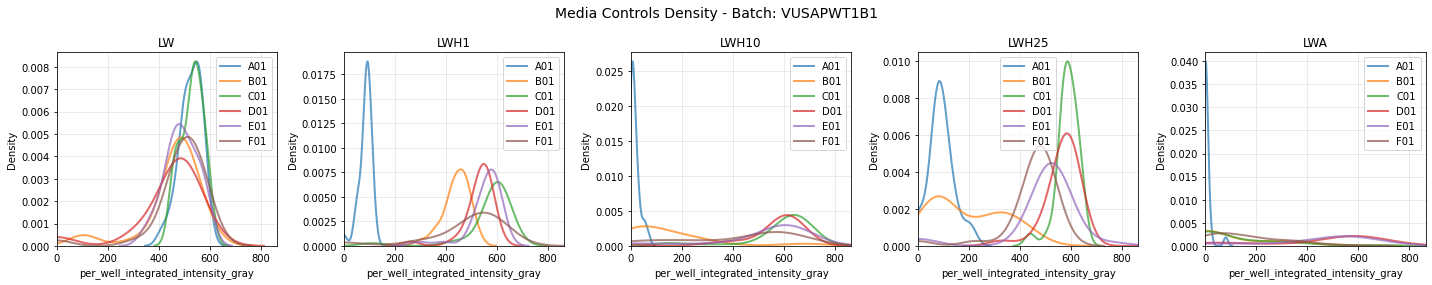

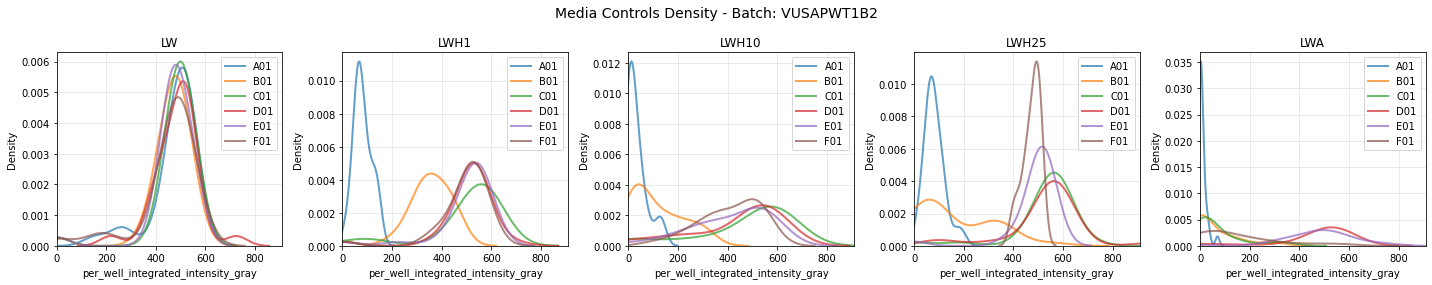

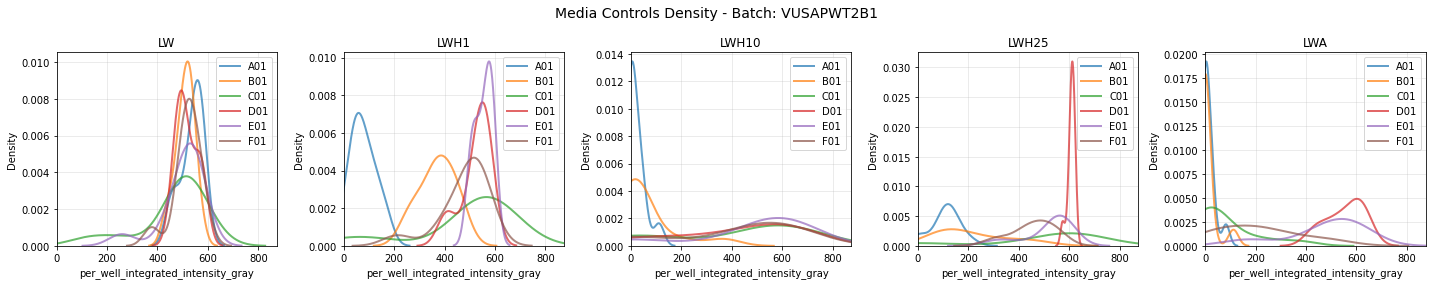

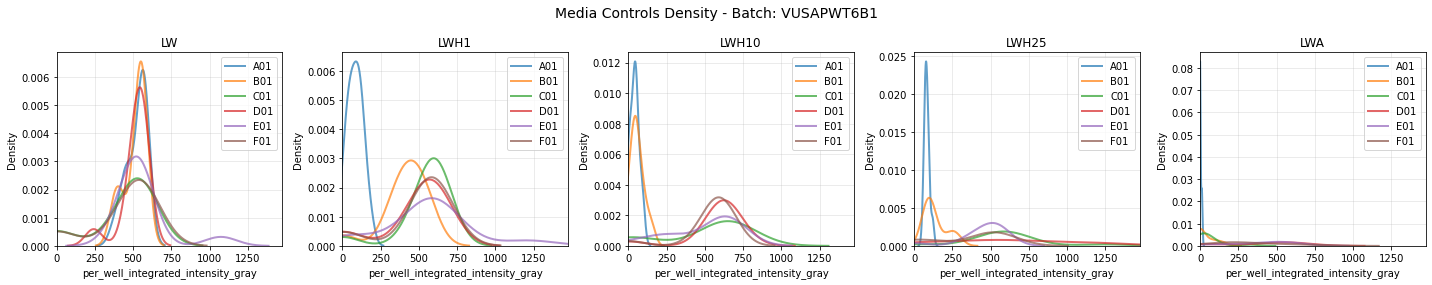

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Get unique retest_batches and condition_names
retest_batches = media_ctrls['retest_batch'].unique()
condition_names = media_ctrls['condition_name'].unique()
condition_names = ['LW', 'LWH1', 'LWH10', 'LWH25', 'LWA']

for batch in retest_batches:
    # Filter data for this batch
    batch_data = media_ctrls[media_ctrls['retest_batch'] == batch]
    
    # Create subplots - one for each condition
    n_conditions = len(condition_names)
    fig, axes = plt.subplots(1, n_conditions, figsize=(4*n_conditions, 4), sharex=True)
    
    # Handle case where there's only one condition
    if n_conditions == 1:
        axes = [axes]
    
    fig.suptitle(f'Media Controls Density - Batch: {batch}', fontsize=14)
    
    for i, condition in enumerate(condition_names):
        ax = axes[i]
        condition_data = batch_data[batch_data['condition_name'] == condition]
        
        if len(condition_data) > 0:
            # Get unique scoring_pos for this condition
            scoring_positions = condition_data['scoring_pos'].unique()
            
            for pos in scoring_positions:
                pos_data = condition_data[condition_data['scoring_pos'] == pos]
                values = pos_data['per_well_integrated_intensity_gray'].values
                
                if len(values) > 0:
                    # Create density curve using seaborn kdeplot
                    sns.kdeplot(x=values, label=f'{pos}', alpha=0.7, linewidth=2, ax=ax)
        
        ax.set_title(f'{condition}')
        ax.set_xlabel('per_well_integrated_intensity_gray')
        ax.set_ylabel('Density')
        ax.set_xlim(left=0)  # Set lower bound of x-axis to 0
        ax.legend()
        ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages

# Get unique retest_batches and condition_names
retest_batches = media_ctrls['retest_batch'].unique()
condition_names = ['LW', 'LWH1', 'LWH10', 'LWH25', 'LWA']

# Create a single figure with subplots for all batches and conditions
n_batches = len(retest_batches)
n_conditions = len(condition_names)

# Create PDF file
with PdfPages(f'{outputs_dir}/sqY2H/media_controls_density_plots.pdf') as pdf:
    fig, axes = plt.subplots(n_batches, n_conditions, figsize=(5*n_conditions, 4*n_batches), sharex=True)#, sharey=True)
    
    # Handle case where there's only one batch
    if n_batches == 1:
        axes = axes.reshape(1, -1)
    # Handle case where there's only one condition
    if n_conditions == 1:
        axes = axes.reshape(-1, 1)
    
    fig.suptitle('Media Controls Density Plots - All Batches', fontsize=16)
    
    for batch_idx, batch in enumerate(retest_batches):
        # Filter data for this batch
        batch_data = media_ctrls[media_ctrls['retest_batch'] == batch]
        
        for condition_idx, condition in enumerate(condition_names):
            ax = axes[batch_idx, condition_idx]
            condition_data = batch_data[batch_data['condition_name'] == condition]
            
            if len(condition_data) > 0:
                # Get unique scoring_pos for this condition
                scoring_positions = condition_data['scoring_pos'].unique()
                
                for pos in scoring_positions:
                    pos_data = condition_data[condition_data['scoring_pos'] == pos]
                    values = pos_data['per_well_integrated_intensity_gray'].values
                    
                    if len(values) > 0:
                        # Create density curve using seaborn kdeplot
                        sns.kdeplot(x=values, label=f'{pos}', alpha=0.7, linewidth=2, ax=ax)
            
            # Set titles and labels
            if batch_idx == 0:
                ax.set_title(f'{condition}', fontsize=12)
            if condition_idx == 0:
                ax.set_ylabel(f'Batch {batch}\nDensity', fontsize=10)
            if batch_idx == n_batches - 1:
                ax.set_xlabel('per_well_integrated_intensity_gray', fontsize=10)
            
            ax.set_xlim(left=0)
            ax.legend(fontsize=8)
            ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    pdf.savefig(fig, bbox_inches='tight')
    plt.close()

print("PDF saved as 'media_controls_density_plots.pdf'")

PDF saved as 'media_controls_density_plots.pdf'


In [22]:
auto_df['per_well_integrated_intensity_gray'] = [700 if x > 700 else x for x in auto_df['per_well_integrated_intensity_gray']]

In [23]:
auto_df[auto_df.per_well_integrated_intensity_gray > 700]

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination


In [24]:
rrs_df = auto_df[
    (auto_df.db_mut_id == 999999.0) &
    (auto_df.condition_name == "LWH1")
    ]
rrs_df

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination
18437,VUSAPWT1B1r03_001,A07,VUSAPWT1B1r03_001_002_003_004_005_006,VUSAPWT1B1,r09,LWH1,1.0,False,279.0,NaN,11451.0,999999.0,RRS_VUS1_DB_1,B01,RRS_VUS1_AD_1,B01,0.0,71.950327,False
18438,VUSAPWT1B1r03_001,A08,VUSAPWT1B1r03_001_002_003_004_005_006,VUSAPWT1B1,r09,LWH1,1.0,False,279.0,NaN,11451.0,999999.0,RRS_VUS1_DB_1,B01,RRS_VUS1_AD_1,B01,0.0,2.230065,False
18485,VUSAPWT1B1r03_001,B07,VUSAPWT1B1r03_001_002_003_004_005_006,VUSAPWT1B1,r09,LWH1,1.0,False,279.0,NaN,11451.0,999999.0,RRS_VUS1_DB_1,B01,RRS_VUS1_AD_1,B01,0.0,45.031373,False
18486,VUSAPWT1B1r03_001,B08,VUSAPWT1B1r03_001_002_003_004_005_006,VUSAPWT1B1,r09,LWH1,1.0,False,279.0,NaN,11451.0,999999.0,RRS_VUS1_DB_1,B01,RRS_VUS1_AD_1,B01,0.0,65.477125,False
18537,VUSAPWT1B1r03_001,C11,VUSAPWT1B1r03_001_002_003_004_005_006,VUSAPWT1B1,r09,LWH1,1.0,False,138.0,NaN,6138.0,999999.0,RRS_VUS1_DB_1,D01,RRS_VUS1_AD_1,D01,0.0,4.296732,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
285654,VUSAPWT1B1r03_033,P08,VUSAPWT1B1r03_031_032_033_034_035_036,VUSAPWT1B1,r09,LWH1,1.0,False,0.0,NaN,4910.0,999999.0,RRS_VUS1_DB_2,A03,CEGSint_Y8A1_2_6,D01,0.0,31.549020,False
285679,VUSAPWT1B1r03_036,P09,VUSAPWT1B1r03_031_032_033_034_035_036,VUSAPWT1B1,r09,LWH1,1.0,False,0.0,NaN,2595.0,999999.0,RRS_VUS1_DB_2,F05,CEGSint_Y8A1_2_6,D01,0.0,25.647059,False
285680,VUSAPWT1B1r03_036,P10,VUSAPWT1B1r03_031_032_033_034_035_036,VUSAPWT1B1,r09,LWH1,1.0,False,0.0,NaN,2595.0,999999.0,RRS_VUS1_DB_2,F05,CEGSint_Y8A1_2_6,D01,0.0,14.950327,False
285681,VUSAPWT1B1r03_036,P11,VUSAPWT1B1r03_031_032_033_034_035_036,VUSAPWT1B1,r09,LWH1,1.0,False,0.0,NaN,7167.0,999999.0,RRS_VUS1_DB_2,H05,CEGSint_Y8A1_2_6,D01,0.0,20.772549,False


146.30559969544504
82.77516439557076
155.5930110874508


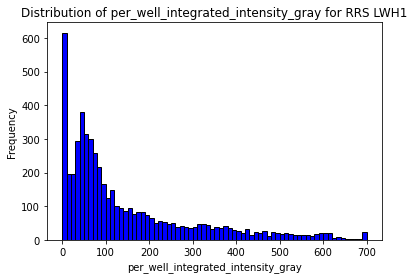

In [25]:
rrs_df.per_well_integrated_intensity_gray.plot.hist(
    bins=70,
    title="Distribution of per_well_integrated_intensity_gray for RRS LWH1",
    xlabel="per_well_integrated_intensity_gray",
    ylabel="Frequency",
    color="blue",
    edgecolor="black"
)

print(rrs_df.per_well_integrated_intensity_gray.mean())
print(rrs_df.per_well_integrated_intensity_gray.median())
print(rrs_df.per_well_integrated_intensity_gray.std())

In [26]:
for group, df in rrs_df.groupby(['ad_orf_id', 'db_orf_id', 'condition_name', 'retest_batch']):
    print(len(df))

4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4
4


In [27]:
print(rrs_df.per_well_integrated_intensity_gray.mean())
print(rrs_df.per_well_integrated_intensity_gray.median())
print(rrs_df.per_well_integrated_intensity_gray.std())

146.30559969544504
82.77516439557076
155.5930110874508


In [28]:
wt_df = auto_df[
    (auto_df.db_mut_id == 0) &
    (auto_df.condition_name == "LWH1")
    ]
wt_df

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination
18433,VUSAPWT1B1r03_001,A03,VUSAPWT1B1r03_001_002_003_004_005_006,VUSAPWT1B1,r09,LWH1,1.0,False,0.0,NaN,2651.0,0.0,DisWTGDEh02,G09,CEGSint_Y8A1_2_6,A01,0.0,56.656210,False
18434,VUSAPWT1B1r03_001,A04,VUSAPWT1B1r03_001_002_003_004_005_006,VUSAPWT1B1,r09,LWH1,1.0,False,0.0,NaN,2651.0,0.0,DisWTGDEh02,G09,CEGSint_Y8A1_2_6,A01,0.0,69.614380,False
18435,VUSAPWT1B1r03_001,A05,VUSAPWT1B1r03_001_002_003_004_005_006,VUSAPWT1B1,r09,LWH1,1.0,False,0.0,NaN,7215.0,0.0,DisWTGDEh03,E01,CEGSint_Y8A1_2_6,A01,0.0,69.550327,False
18436,VUSAPWT1B1r03_001,A06,VUSAPWT1B1r03_001_002_003_004_005_006,VUSAPWT1B1,r09,LWH1,1.0,False,0.0,NaN,7215.0,0.0,DisWTGDEh03,E01,CEGSint_Y8A1_2_6,A01,0.0,56.546406,False
18439,VUSAPWT1B1r03_001,A09,VUSAPWT1B1r03_001_002_003_004_005_006,VUSAPWT1B1,r09,LWH1,1.0,False,0.0,NaN,100016069.0,0.0,DisWTGDEh03,G03,CEGSint_Y8A1_2_6,A01,0.0,51.261438,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
233544,VUSAPWT6B1r03_027,D02,VUSAPWT6B1r03_025_026_027_xxx_xxx_xxx,VUSAPWT6B1,r15,LWH1,6.0,False,7617.0,NaN,9726.0,0.0,DisWTY8Dh02,B01,CEGSint_Y8A6_3,D04,0.0,54.056210,False
233663,VUSAPWT6B1r03_027,I01,VUSAPWT6B1r03_025_026_027_xxx_xxx_xxx,VUSAPWT6B1,r15,LWH1,6.0,False,0.0,NaN,9726.0,0.0,DisWTY8Dh02,B01,CEGSint_Y8A6_3,D10,0.0,517.492829,False
233664,VUSAPWT6B1r03_027,I02,VUSAPWT6B1r03_025_026_027_xxx_xxx_xxx,VUSAPWT6B1,r15,LWH1,6.0,False,0.0,NaN,9726.0,0.0,DisWTY8Dh02,B01,CEGSint_Y8A6_3,D10,0.0,112.300656,False
233687,VUSAPWT6B1r03_027,J01,VUSAPWT6B1r03_025_026_027_xxx_xxx_xxx,VUSAPWT6B1,r15,LWH1,6.0,False,0.0,NaN,9726.0,0.0,DisWTY8Dh02,B01,CEGSint_Y8A6_3,D10,0.0,411.972558,False


mean 342.64768647143126
median 419.9006679356098
std 232.71842816833066


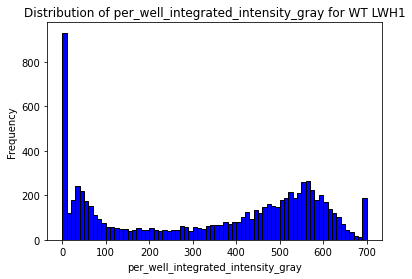

In [29]:
wt_df.per_well_integrated_intensity_gray.plot.hist(
    bins=70,
    title="Distribution of per_well_integrated_intensity_gray for WT LWH1",
    xlabel="per_well_integrated_intensity_gray",
    ylabel="Frequency",
    color="blue",
    edgecolor="black"
)

print('mean', wt_df.per_well_integrated_intensity_gray.mean())
print('median', wt_df.per_well_integrated_intensity_gray.median())
print('std', wt_df.per_well_integrated_intensity_gray.std())

In [30]:
wt_df.per_well_integrated_intensity_gray.mean()

342.64768647143126

In [31]:
wt_df.per_well_integrated_intensity_gray.median()

419.9006679356098

In [32]:
wt_df.per_well_integrated_intensity_gray.std()

232.71842816833066

In [33]:
scoring_conditions = ['LWH1', 'LWH10', 'LWH25', 'LWA']
max_score = 4
aa_id = '0.0'
rrs_id = 999999.0

<Axes: ylabel='Frequency'>

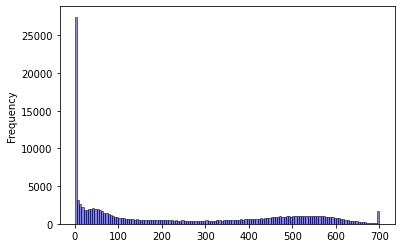

In [34]:
auto_df[
    (auto_df['condition_name'].isin(scoring_conditions)) &
    (auto_df.media_control == False) &
    (auto_df['ad_orf_id'] != aa_id) &
    (auto_df['db_mut_id'] != 999999.0)
].per_well_integrated_intensity_gray.plot(kind='hist', bins=140, alpha=0.5, color='blue', edgecolor='black')#, xlim=(0, 100), ylim=(0, 2000))

<Axes: ylabel='Frequency'>

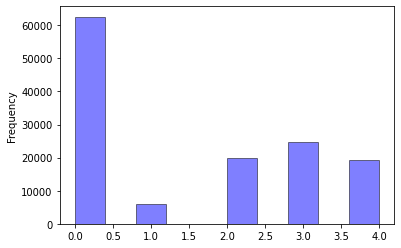

In [35]:
auto_df[
    (auto_df['condition_name'].isin(scoring_conditions)) &
    (auto_df.media_control == False) &
    (auto_df['ad_orf_id'] != aa_id) &
    (auto_df['db_mut_id'] != 999999.0)
].manual_score_growth.plot(kind='hist', alpha=0.5, color='blue', edgecolor='black')#, xlim=(0, 100), ylim=(0, 2000))

In [36]:
# rest_df = auto_df[
#     ~(
#         (auto_df['condition_name'].isin(scoring_conditions)) &
#         (auto_df.media_control == False) #&
#         # (auto_df['ad_orf_id'] != aa_id) &
#         # (auto_df['db_mut_id'] != 999999.0)
#     )
# ]

In [37]:
import matplotlib.pyplot as plt

(array([2.6714e+04, 1.0749e+04, 6.9830e+03, 4.9360e+03, 3.4440e+03,
        2.5480e+03, 1.8990e+03, 1.4750e+03, 1.2830e+03, 1.0380e+03,
        8.8800e+02, 7.8500e+02, 6.4900e+02, 5.8100e+02, 4.7700e+02,
        4.8700e+02, 3.7600e+02, 3.1700e+02, 2.9700e+02, 3.1300e+02,
        2.5600e+02, 2.4700e+02, 2.4000e+02, 2.2400e+02, 2.0300e+02,
        2.1600e+02, 1.9300e+02, 1.8500e+02, 2.0700e+02, 1.9600e+02,
        2.2800e+02, 2.3900e+02, 2.3000e+02, 2.4300e+02, 2.6000e+02,
        2.5600e+02, 2.1500e+02, 2.1400e+02, 2.2800e+02, 1.8800e+02,
        2.0100e+02, 1.4800e+02, 1.1700e+02, 1.1700e+02, 1.0100e+02,
        6.1000e+01, 4.4000e+01, 3.4000e+01, 2.1000e+01, 1.5500e+02]),
 array([  0.,   7.,  14.,  21.,  28.,  35.,  42.,  49.,  56.,  63.,  70.,
         77.,  84.,  91.,  98., 105., 112., 119., 126., 133., 140., 147.,
        154., 161., 168., 175., 182., 189., 196., 203., 210., 217., 224.,
        231., 238., 245., 252., 259., 266., 273., 280., 287., 294., 301.,
        308., 315., 32

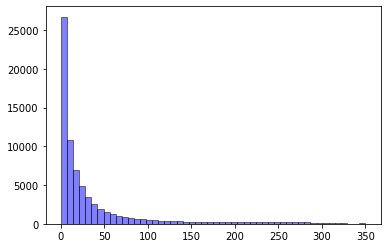

In [38]:
mads = []

mad_tuples = []

test_tuple = []

valid_tuple = []
failed_tuple = []

mode_diffs = []


for group, df in auto_df.groupby(['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']):
    scores = df['per_well_integrated_intensity_gray'].values
    # compute the Median absolute deviation (MAD) of the scores
    median = np.median(scores)
    mean = np.mean(scores)
    mad = np.median(np.abs(scores - median))
    valid_range = [median + ( 2 * mad), median - ( 2 *mad)]
    std = np.std(scores)
    cv = std / mean if mean != 0 else 0
    rmad = mad / median if median != 0 else 0
    sorted_scores = np.sort(scores)
    if len(sorted_scores) == 4:
        mode_diff = np.abs(np.mean(sorted_scores[-2:]) - np.mean(sorted_scores[:2]))
    else:
        mode_diff = np.nan
    
    mode_diffs.append(mode_diff)
    
    valid_scores = scores[(scores >= valid_range[1]) & (scores <= valid_range[0])]
    mean_valid = np.mean(valid_scores) if len(valid_scores) > 0 else 0
    
    if rmad < 0.5:
        valid_tuple.append((scores, valid_scores, valid_range, mad, median, mean_valid, std, cv, rmad))
    else:
        failed_tuple.append((scores, valid_scores, valid_range, mad, median, mean_valid, std, cv, rmad))
    
    test_tuple.append((scores, valid_scores, valid_range, mad, median, mean_valid, std, cv, rmad, mode_diff))
    
    mad_over_median = mad / median if median != 0 else 0
    mad_over_mean = mad / mean if mean != 0 else 0
    # compute the z-score of each score
    z_scores = (scores - median) / mad if mad != 0 else np.zeros(len(scores))
    # print the group and the z-scores
    # print(f"Group: {group}\nValues: {scores}\nMAD: {mad}\nZ-scores: {z_scores}\n")
    mads.append(mad)
    mad_tuples.append((mad, scores, mad_over_median, median, mad_over_mean, mean, mode_diff))

plt.hist(mads, bins=50, alpha=0.5, color='blue', edgecolor='black')    

(array([2.6714e+04, 1.0749e+04, 6.9830e+03, 4.9360e+03, 3.4440e+03,
        2.5480e+03, 1.8990e+03, 1.4750e+03, 1.2830e+03, 1.0380e+03,
        8.8800e+02, 7.8500e+02, 6.4900e+02, 5.8100e+02, 4.7700e+02,
        4.8700e+02, 3.7600e+02, 3.1700e+02, 2.9700e+02, 3.1300e+02,
        2.5600e+02, 2.4700e+02, 2.4000e+02, 2.2400e+02, 2.0300e+02,
        2.1600e+02, 1.9300e+02, 1.8500e+02, 2.0700e+02, 1.9600e+02,
        2.2800e+02, 2.3900e+02, 2.3000e+02, 2.4300e+02, 2.6000e+02,
        2.5600e+02, 2.1500e+02, 2.1400e+02, 2.2800e+02, 1.8800e+02,
        2.0100e+02, 1.4800e+02, 1.1700e+02, 1.1700e+02, 1.0100e+02,
        6.1000e+01, 4.4000e+01, 3.4000e+01, 2.1000e+01, 1.5500e+02]),
 array([  0.,   7.,  14.,  21.,  28.,  35.,  42.,  49.,  56.,  63.,  70.,
         77.,  84.,  91.,  98., 105., 112., 119., 126., 133., 140., 147.,
        154., 161., 168., 175., 182., 189., 196., 203., 210., 217., 224.,
        231., 238., 245., 252., 259., 266., 273., 280., 287., 294., 301.,
        308., 315., 32

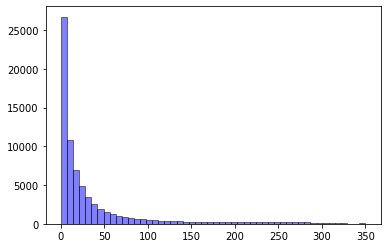

In [39]:
mads = []

mad_tuples = []

test_tuple = []

valid_tuple = []
failed_tuple = []

mode_diffs = []


for group, df in auto_df.groupby(['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']):
    scores = df['per_well_integrated_intensity_gray'].values
    # compute the Median absolute deviation (MAD) of the scores
    median = np.median(scores)
    mean = np.mean(scores)
    mad = np.median(np.abs(scores - median))
    valid_range = [median + ( 2 * mad), median - ( 2 *mad)]
    std = np.std(scores)
    cv = std / mean if mean != 0 else 0
    rmad = mad / median if median != 0 else 0
    sorted_scores = np.sort(scores)
    if len(sorted_scores) == 4:
        mode_diff = np.abs(np.mean(sorted_scores[-2:]) - np.mean(sorted_scores[:2]))
    else:
        mode_diff = np.nan
    
    mode_diffs.append(mode_diff)
    
    # if mad < 50 and mode_diff > 300:
    #     print(sorted_scores)
    #     print(median)
    
    valid_scores = scores[(scores >= valid_range[1]) & (scores <= valid_range[0])]
    mean_valid = np.mean(valid_scores) if len(valid_scores) > 0 else 0
    
    if rmad < 0.5:
        valid_tuple.append((scores, valid_scores, valid_range, mad, median, mean_valid, std, cv, rmad))
    else:
        failed_tuple.append((scores, valid_scores, valid_range, mad, median, mean_valid, std, cv, rmad))
    
    test_tuple.append((scores, valid_scores, valid_range, mad, median, mean_valid, std, cv, rmad, mode_diff))
    
    mad_over_median = mad / median if median != 0 else 0
    mad_over_mean = mad / mean if mean != 0 else 0
    # compute the z-score of each score
    z_scores = (scores - median) / mad if mad != 0 else np.zeros(len(scores))
    # print the group and the z-scores
    # print(f"Group: {group}\nValues: {scores}\nMAD: {mad}\nZ-scores: {z_scores}\n")
    mads.append(mad)
    mad_tuples.append((mad, scores, mad_over_median, median, mad_over_mean, mean, mode_diff))

plt.hist(mads, bins=50, alpha=0.5, color='blue', edgecolor='black')    

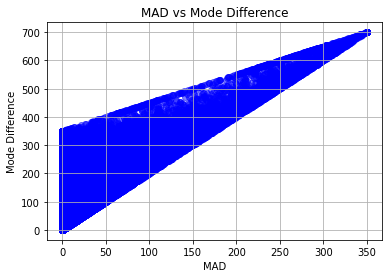

In [40]:
# scatterplot mad vs mode_diff
plt.scatter(mads, mode_diffs, alpha=0.5, color='blue')
plt.xlabel('MAD')
plt.ylabel('Mode Difference')
plt.title('MAD vs Mode Difference')
plt.grid(True)
plt.show()

In [41]:
# find cases where NAD is low but mode_diff is high
low_mad_high_mode_diff = [
    (mad, mode_diff) for mad, mode_diff in zip(mads, mode_diffs)
    if mad < 0.5 and mode_diff > 0.5
]

In [42]:
# 75th percentile of MADs
mad_75 = np.percentile(mads, 95)
print(f"75th percentile of MADs: {mad_75}")

75th percentile of MADs: 200.03464555740356


In [43]:
mads75 = [x for x in mads if x < mad_75]

len(mads75)/ len(mads)

0.9499902379159345

In [44]:
# test_tuple = sorted(test_tuple, key=lambda x: x[3], reverse=True)

# for scores, valid_scores, valid_range, mad, median, mean_valid, std, cv, rmad, mode_diff in test_tuple:
#     print('Replicates', scores)
#     print('Valid', valid_scores)
#     print('Mean valid', mean_valid)
#     print('Median +- MAD', valid_range)
#     print('MAD', mad)
#     print('Median', median)
#     print('Mean', np.mean(scores))
#     print('Std', std)
#     print('CV', cv)
#     print('RMAD', rmad)
#     print('Mode difference', mode_diff)
#     print('---')
#     print()

In [45]:
len(valid_tuple)/len(test_tuple)

0.7888879591665969

In [46]:
# valid_tuple = sorted(valid_tuple, key=lambda x: x[3], reverse=True)

# for scores, valid_scores, valid_range, mad, median, mean_valid, std, cv, rmad in valid_tuple:
#     print('Replicates', scores)
#     print('Valid', valid_scores)
#     print('Mean valid', mean_valid)
#     print('Median +- MAD', valid_range)
#     print('MAD', mad)
#     print('Median', median)
#     print('Mean', np.mean(scores))
#     print('Std', std)
#     print('CV', cv)
#     print('RMAD', rmad)
#     print()

In [47]:
# failed_tuple = sorted(failed_tuple, key=lambda x: x[3], reverse=True)

# for scores, valid_scores, valid_range, mad, median, mean_valid, std, cv, rmad in failed_tuple:
#     print('Replicates', scores)
#     print('Valid', valid_scores)
#     print('Mean valid', mean_valid)
#     print('Median +- MAD', valid_range)
#     print('MAD', mad)
#     print('Median', median)
#     print('Mean', np.mean(scores))
#     print('Std', std)
#     print('CV', cv)
#     print('RMAD', rmad)
#     print()

In [48]:
scores = np.array([385.23791552,  47.60130751,  29.98431396,  53.13725534])
median = np.median(scores)
mean = np.mean(scores)
mad = np.median(np.abs(scores - median))
valid_range = [median + ( 2 * mad), median - ( 2 *mad)]
std = np.std(scores)
cv = std / mean if mean != 0 else 0


valid_scores = scores[(scores >= valid_range[1]) & (scores <= valid_range[0])]
mean_valid = np.mean(valid_scores) if len(valid_scores) > 0 else 0

print('Replicates', scores)
print('Valid', valid_scores)
print('Mean valid', mean_valid)
print('Median +- MAD', valid_range)
print('MAD', mad)
print('Median', median)
print('Mean', np.mean(scores))
print('Std', std)
print('CV', cv)


Replicates [385.23791552  47.60130751  29.98431396  53.13725534]
Valid [47.60130751 29.98431396 53.13725534]
Mean valid 43.57429227
Median +- MAD [73.522222805, 27.216340044999995]
MAD 11.57647069
Median 50.369281425
Mean 128.9901980825
Std 148.19149622542963
CV 1.1488585832750546


In [49]:
scores = np.array([385.23791552,  410.23414,  350.1234145,  53.13725534])
median = np.median(scores)
mean = np.mean(scores)
mad = np.median(np.abs(scores - median))
valid_range = [median + ( 2 * mad), median - ( 2 *mad)]
std = np.std(scores)
cv = std / mean if mean != 0 else 0


valid_scores = scores[(scores >= valid_range[1]) & (scores <= valid_range[0])]
mean_valid = np.mean(valid_scores) if len(valid_scores) > 0 else 0

print('Replicates', scores)
print('Valid', valid_scores)
print('Mean valid', mean_valid)
print('Median +- MAD', valid_range)
print('MAD', mad)
print('Median', median)
print('Mean', np.mean(scores))
print('Std', std)
print('CV', cv)


Replicates [385.23791552 410.23414    350.1234145   53.13725534]
Valid [385.23791552 410.23414    350.1234145 ]
Mean valid 381.86515667333333
Median +- MAD [427.79139051000004, 307.5699395099999]
MAD 30.05536275000003
Median 367.68066501
Mean 299.68318134
Std 143.93595602705403
CV 0.48029374015405346


In [50]:
len(mad_tuples)

71706

In [51]:
# sorted_tuple = sorted(mad_tuples, key=lambda x: x[0], reverse=True)
# for mad, scores, mad_over_median, median in sorted_tuple:
#     if len(scores) < 2:
#         continue
#     print(f"MAD: {mad}, Scores: {sorted(scores)}, MAD/Median: {mad_over_median}, Median: {median}, diff between two modes {np.mean([sorted(scores)[-1], sorted(scores)[-2]]) - np.mean([sorted(scores)[0], sorted(scores)[1]])}")

In [52]:
arr_1 = [25, 25, 50, 50]
arr_2 = [300, 300, 600, 600]

median = np.median(arr_1)
mad = np.median(np.abs(arr_1 - median))
# compute the z-score of each score
z_scores = (arr_1 - median) / mad if mad != 0 else np.zeros(len(arr_1))

print(f"Values: {arr_1}\nMAD: {mad}\nZ-scores: {z_scores}\n")

median = np.median(arr_2)
mad = np.median(np.abs(arr_2 - median))
# compute the z-score of each score
z_scores = (arr_2 - median) / mad if mad != 0 else np.zeros(len(arr_2))

print(f"Values: {arr_2}\nMAD: {mad}\nZ-scores: {z_scores}\n")

Values: [25, 25, 50, 50]
MAD: 12.5
Z-scores: [-1. -1.  1.  1.]

Values: [300, 300, 600, 600]
MAD: 150.0
Z-scores: [-1. -1.  1.  1.]



In [53]:
# get 75th percentile values of array

# arr_1 = [0, 0, 0, 700]

# arr_2 = [700, 700, 700, 0]





In [54]:
arr_1 = [0, 0, 0, 700]
arr_2 = [700, 700, 700, 0]

median = np.median(arr_1)
mad = np.median(np.abs(arr_1 - median))
mean = np.mean(arr_1)
# compute the z-score of each score
z_scores = (arr_1 - median) / mad if mad != 0 else np.zeros(len(arr_1))

print(f"Values: {arr_1}\nMAD: {mad}\n mean:{mean}\nZ-scores: {z_scores}\n")

median = np.median(arr_2)
mad = np.median(np.abs(arr_2 - median))
mean = np.mean(arr_2)
# compute the z-score of each score
z_scores = (arr_2 - median) / mad if mad != 0 else np.zeros(len(arr_2))

print(f"Values: {arr_2}\nMAD: {mad}\n mean:{mean}\nZ-scores: {z_scores}\n")

Values: [0, 0, 0, 700]
MAD: 0.0
 mean:175.0
Z-scores: [0. 0. 0. 0.]

Values: [700, 700, 700, 0]
MAD: 0.0
 mean:525.0
Z-scores: [0. 0. 0. 0.]



<Axes: ylabel='Frequency'>

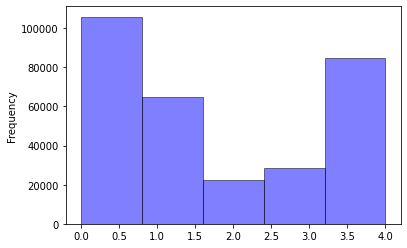

In [55]:
# Consensus

scoring_df = auto_df.copy()
#[
    # (auto_df['condition_name'].isin(scoring_conditions)) &
    # (auto_df.media_control == False) #&
    # (auto_df['ad_orf_id'] != aa_id) &
    # (auto_df['db_mut_id'] != 999999.0)
#

def continuous_to_discrete(score):
    if score < 20:
        return 0
    elif 20 <= score < 150:
        return 1
    elif 150 <= score < 300:
        return 2
    elif 300 <= score < 450:
        return 3
    elif score >= 450:
        return 4
    else:
        return np.nan
    
scoring_df['continuous_bin'] = scoring_df['per_well_integrated_intensity_gray'].apply(continuous_to_discrete)

scoring_df['continuous_bin'].plot(kind='hist', bins=5, alpha=0.5, color='blue', edgecolor='black')

In [56]:
mode_stats = scoring_df.groupby(['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch'])['continuous_bin'].agg([
    lambda x: x.mode().tolist(),  # mode values
    lambda x: len(x.mode())       # number of modes
]).reset_index()


mode_stats.columns = ['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch', 'mode_values', 'num_modes']

print("Mode statistics:")
print(mode_stats.head(10))

# Show distribution of number of modes
print("\nDistribution of number of modes:")
print(mode_stats['num_modes'].value_counts().sort_index())

mode_stats

scoring_df = scoring_df.merge(mode_stats, on=['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch'], how='left')
scoring_df

Mode statistics:
  ad_orf_id    db_orf_id  db_mut_id condition_name retest_batch mode_values  \
0       0.0  100000400.0        0.0             LW   VUSAPWT1B2      [3, 4]   
1       0.0  100000400.0        0.0            LWA   VUSAPWT1B2         [0]   
2       0.0  100000400.0        0.0          LWAH1   VUSAPWT1B2         [0]   
3       0.0  100000400.0        0.0           LWH1   VUSAPWT1B2         [1]   
4       0.0  100000400.0        0.0          LWH10   VUSAPWT1B2         [0]   
5       0.0  100000400.0        0.0          LWH25   VUSAPWT1B2         [1]   
6       0.0  100000400.0   221523.0             LW   VUSAPWT1B2      [0, 1]   
7       0.0  100000400.0   221523.0            LWA   VUSAPWT1B2         [3]   
8       0.0  100000400.0   221523.0          LWAH1   VUSAPWT1B2         [0]   
9       0.0  100000400.0   221523.0           LWH1   VUSAPWT1B2         [0]   

   num_modes  
0          2  
1          1  
2          1  
3          1  
4          1  
5          1  
6       

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,continuous_bin,mode_values,num_modes
0,VUSAPWT1B1r01_001,A01,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,True,A01_1,NaN,...,DB_hap_ctrl,A10,AD_hap_ctrl,A10,4.0,490.572572,False,4,NaN,NaN
1,VUSAPWT1B1r01_001,A02,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,True,A01_1,NaN,...,DB_hap_ctrl,A10,AD_hap_ctrl,A10,4.0,521.929437,False,4,NaN,NaN
2,VUSAPWT1B1r01_001,A03,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,DisWTGDEh02,G09,CEGSint_Y8A1_2_6,A01,4.0,455.656230,False,4,[4],1.0
3,VUSAPWT1B1r01_001,A04,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,DisWTGDEh02,G09,CEGSint_Y8A1_2_6,A01,4.0,544.304600,False,4,[4],1.0
4,VUSAPWT1B1r01_001,A05,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,DisWTGDEh03,E01,CEGSint_Y8A1_2_6,A01,4.0,505.925513,False,4,[4],1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
306426,VUSAPWT1B1r06_036,P20,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,...,VUSMutY8Dh022,H09,CEGSint_Y8A_6,E11,2.0,435.596088,False,3,"[0, 2, 3, 4]",4.0
306427,VUSAPWT1B1r06_036,P21,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,...,VUSMutY8Dh022,B10,CEGSint_Y8A_6,E11,2.0,700.000000,False,4,[4],1.0
306428,VUSAPWT1B1r06_036,P22,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,...,VUSMutY8Dh022,B10,CEGSint_Y8A_6,E11,2.0,700.000000,False,4,[4],1.0
306429,VUSAPWT1B1r06_036,P23,VUSAPWT1B1r06_031_032_033_034_035_036,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,5.239216,True,0,NaN,NaN


In [57]:
for group, df in scoring_df[scoring_df.num_modes == 3].groupby(['ad_orf_id', 'db_orf_id', 'condition_name', 'retest_batch']):
    break


df

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,continuous_bin,mode_values,num_modes
139894,VUSAPWT1B2r06_012,C01,VUSAPWT1B2r06_007_008_009_010_011_012,VUSAPWT1B2,r12,LWAH1,1.0,False,0.0,NaN,...,DisWTY8Dh04,H05,CEGSint_Y8A1_2_6,B01,0.0,309.254908,False,3,"[2, 3, 4]",3.0
139895,VUSAPWT1B2r06_012,C02,VUSAPWT1B2r06_007_008_009_010_011_012,VUSAPWT1B2,r12,LWAH1,1.0,False,0.0,NaN,...,DisWTY8Dh04,H05,CEGSint_Y8A1_2_6,B01,0.0,268.052294,False,2,"[2, 3, 4]",3.0
139918,VUSAPWT1B2r06_012,C01,VUSAPWT1B2r06_007_008_009_010_011_012,VUSAPWT1B2,r12,LWAH1,1.0,False,0.0,NaN,...,DisWTY8Dh04,H05,CEGSint_Y8A1_2_6,B01,0.0,628.203948,False,4,"[2, 3, 4]",3.0
139942,VUSAPWT1B2r06_012,D01,VUSAPWT1B2r06_007_008_009_010_011_012,VUSAPWT1B2,r12,LWAH1,1.0,False,0.0,NaN,...,DisWTY8Dh04,H05,CEGSint_Y8A1_2_6,B01,0.0,301.984320,False,3,"[2, 3, 4]",3.0
139943,VUSAPWT1B2r06_012,D02,VUSAPWT1B2r06_007_008_009_010_011_012,VUSAPWT1B2,r12,LWAH1,1.0,False,0.0,NaN,...,DisWTY8Dh04,H05,CEGSint_Y8A1_2_6,B01,0.0,199.501965,False,2,"[2, 3, 4]",3.0
139966,VUSAPWT1B2r06_012,D01,VUSAPWT1B2r06_007_008_009_010_011_012,VUSAPWT1B2,r12,LWAH1,1.0,False,0.0,NaN,...,DisWTY8Dh04,H05,CEGSint_Y8A1_2_6,B01,0.0,620.526824,False,4,"[2, 3, 4]",3.0


In [58]:
# Select groups with a single mode
consensus_easy = scoring_df[scoring_df['num_modes'] == 1]

# Compute mean per group
consensus_easy_mean = consensus_easy.groupby(
    ['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']
)['per_well_integrated_intensity_gray'].mean().reset_index().rename(
    columns={'per_well_integrated_intensity_gray': 'consensus_score'}
)

# Merge the consensus_score back to consensus_easy for full rows
consensus_easy = consensus_easy.merge(
    consensus_easy_mean,
    on=['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch'],
    how='left'
)

consensus_easy

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,continuous_bin,mode_values,num_modes,consensus_score
0,VUSAPWT1B1r01_001,A03,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,G09,CEGSint_Y8A1_2_6,A01,4.0,455.656230,False,4,[4],1.0,494.701983
1,VUSAPWT1B1r01_001,A04,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,G09,CEGSint_Y8A1_2_6,A01,4.0,544.304600,False,4,[4],1.0,494.701983
2,VUSAPWT1B1r01_001,A05,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,E01,CEGSint_Y8A1_2_6,A01,4.0,505.925513,False,4,[4],1.0,512.738259
3,VUSAPWT1B1r01_001,A06,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,E01,CEGSint_Y8A1_2_6,A01,4.0,536.567345,False,4,[4],1.0,512.738259
4,VUSAPWT1B1r01_001,A07,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,279.0,NaN,...,B01,RRS_VUS1_AD_1,B01,4.0,498.666689,False,4,[4],1.0,532.806560
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
244052,VUSAPWT1B1r06_036,P12,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,0.0,NaN,...,H05,CEGSint_Y8A1_2_6,D01,0.0,0.000000,False,0,[0],1.0,117.067323
244053,VUSAPWT1B1r06_036,P17,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,53212.0,NaN,...,G09,CEGSint_Y8A_7,F04,2.0,73.048367,False,1,[1],1.0,178.228434
244054,VUSAPWT1B1r06_036,P18,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,53212.0,NaN,...,G09,CEGSint_Y8A_7,F04,2.0,412.423535,False,3,[1],1.0,178.228434
244055,VUSAPWT1B1r06_036,P21,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,...,B10,CEGSint_Y8A_6,E11,2.0,700.000000,False,4,[4],1.0,484.866017


In [59]:
scoring_df

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,continuous_bin,mode_values,num_modes
0,VUSAPWT1B1r01_001,A01,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,True,A01_1,NaN,...,DB_hap_ctrl,A10,AD_hap_ctrl,A10,4.0,490.572572,False,4,NaN,NaN
1,VUSAPWT1B1r01_001,A02,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,True,A01_1,NaN,...,DB_hap_ctrl,A10,AD_hap_ctrl,A10,4.0,521.929437,False,4,NaN,NaN
2,VUSAPWT1B1r01_001,A03,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,DisWTGDEh02,G09,CEGSint_Y8A1_2_6,A01,4.0,455.656230,False,4,[4],1.0
3,VUSAPWT1B1r01_001,A04,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,DisWTGDEh02,G09,CEGSint_Y8A1_2_6,A01,4.0,544.304600,False,4,[4],1.0
4,VUSAPWT1B1r01_001,A05,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,DisWTGDEh03,E01,CEGSint_Y8A1_2_6,A01,4.0,505.925513,False,4,[4],1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
306426,VUSAPWT1B1r06_036,P20,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,...,VUSMutY8Dh022,H09,CEGSint_Y8A_6,E11,2.0,435.596088,False,3,"[0, 2, 3, 4]",4.0
306427,VUSAPWT1B1r06_036,P21,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,...,VUSMutY8Dh022,B10,CEGSint_Y8A_6,E11,2.0,700.000000,False,4,[4],1.0
306428,VUSAPWT1B1r06_036,P22,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,...,VUSMutY8Dh022,B10,CEGSint_Y8A_6,E11,2.0,700.000000,False,4,[4],1.0
306429,VUSAPWT1B1r06_036,P23,VUSAPWT1B1r06_031_032_033_034_035_036,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,5.239216,True,0,NaN,NaN


In [60]:
# Select groups with a single mode
consensus_easy = scoring_df[scoring_df['num_modes'] == 1]

# Function to compute mean for values within 1 bin of the mode, with special handling for mode=0
def mean_of_mode_and_adjacent_values(group):
    mode_bin = group['mode_values'].iloc[0][0]  # Get the single mode value
    
    if mode_bin == 0:
        # Special case: if mode is 0, check if non-zero values are close to each other
        non_zero_values = group[group['continuous_bin'] != 0]['continuous_bin']
        if len(non_zero_values) >= 2:
            # Check if the non-zero values are close to each other (within 1 bin)
            non_zero_unique = non_zero_values.unique()
            if len(non_zero_unique) >= 2:
                max_diff = max(non_zero_unique) - min(non_zero_unique)
                if max_diff <= 1:  # Non-zero values are close to each other
                    # Take the non-zero values instead of mode
                    close_to_mode_mask = group['continuous_bin'] != 0
                else:
                    # Non-zero values are not close, use standard rule
                    close_to_mode_mask = abs(group['continuous_bin'] - mode_bin) <= 1
            else:
                # Only one unique non-zero value, use standard rule
                close_to_mode_mask = abs(group['continuous_bin'] - mode_bin) <= 1
        else:
            # Less than 2 non-zero values, use standard rule
            close_to_mode_mask = abs(group['continuous_bin'] - mode_bin) <= 1
    else:
        # Standard case: filter to values where continuous_bin is within 1 of the mode
        close_to_mode_mask = abs(group['continuous_bin'] - mode_bin) <= 1
    
    close_intensity_values = group.loc[close_to_mode_mask, 'per_well_integrated_intensity_gray']
    return close_intensity_values.mean()

# Compute mean for values within 1 bin of the mode
consensus_easy_mean = consensus_easy.groupby(
    ['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']
).apply(mean_of_mode_and_adjacent_values).reset_index().rename(
    columns={0: 'consensus_score'}
)

# Merge the consensus_score back to consensus_easy for full rows
consensus_easy = consensus_easy.merge(
    consensus_easy_mean,
    on=['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch'],
    how='left'
)

consensus_easy

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_46272/2048419143.py:36: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  consensus_easy_mean = consensus_easy.groupby(


,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,continuous_bin,mode_values,num_modes,consensus_score
0,VUSAPWT1B1r01_001,A03,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,G09,CEGSint_Y8A1_2_6,A01,4.0,455.656230,False,4,[4],1.0,494.701983
1,VUSAPWT1B1r01_001,A04,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,G09,CEGSint_Y8A1_2_6,A01,4.0,544.304600,False,4,[4],1.0,494.701983
2,VUSAPWT1B1r01_001,A05,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,E01,CEGSint_Y8A1_2_6,A01,4.0,505.925513,False,4,[4],1.0,512.738259
3,VUSAPWT1B1r01_001,A06,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,E01,CEGSint_Y8A1_2_6,A01,4.0,536.567345,False,4,[4],1.0,512.738259
4,VUSAPWT1B1r01_001,A07,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,279.0,NaN,...,B01,RRS_VUS1_AD_1,B01,4.0,498.666689,False,4,[4],1.0,532.806560
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
244052,VUSAPWT1B1r06_036,P12,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,0.0,NaN,...,H05,CEGSint_Y8A1_2_6,D01,0.0,0.000000,False,0,[0],1.0,0.000000
244053,VUSAPWT1B1r06_036,P17,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,53212.0,NaN,...,G09,CEGSint_Y8A_7,F04,2.0,73.048367,False,1,[1],1.0,100.163400
244054,VUSAPWT1B1r06_036,P18,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,53212.0,NaN,...,G09,CEGSint_Y8A_7,F04,2.0,412.423535,False,3,[1],1.0,100.163400
244055,VUSAPWT1B1r06_036,P21,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,...,B10,CEGSint_Y8A_6,E11,2.0,700.000000,False,4,[4],1.0,646.488022


In [61]:
# for group, df in consensus_easy.groupby(['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']):
#     print('bins',df.continuous_bin.values)
#     print('num modes',df.num_modes.values)
#     print('mode values',df.mode_values.values)
#     print(df.per_well_integrated_intensity_gray.values)
#     print(df.consensus_score.values[0])

In [62]:
# Handle groups with exactly 2 modes
consensus_hard = scoring_df[scoring_df['num_modes'] == 2]

# Function to handle groups with 2 modes
def handle_two_modes(group):
    mode_values = group['mode_values'].iloc[0]  # Get the two mode values
    mode_diff = abs(mode_values[0] - mode_values[1])
    
    if mode_diff == 1:
        # Modes are consecutive (differ by 1), take mean of both mode bins
        mode_mask = group['continuous_bin'].isin(mode_values)
        mode_intensity_values = group.loc[mode_mask, 'per_well_integrated_intensity_gray']
        return mode_intensity_values.mean()
    elif 0 in mode_values and mode_diff > 1:
        # Special case: one mode is 0 and they're not consecutive
        # Take the non-zero mode
        non_zero_mode = [mode for mode in mode_values if mode != 0][0]
        mode_mask = group['continuous_bin'] == non_zero_mode
        mode_intensity_values = group.loc[mode_mask, 'per_well_integrated_intensity_gray']
        return mode_intensity_values.mean()
    else:
        # Modes are not consecutive and neither is 0, discard the group
        return np.nan

# Compute consensus scores for hard cases
consensus_hard_mean = consensus_hard.groupby(
    ['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']
).apply(handle_two_modes).reset_index().rename(
    columns={0: 'consensus_score'}
)

# Merge the consensus_score back to consensus_hard for full rows
consensus_hard = consensus_hard.merge(
    consensus_hard_mean,
    on=['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch'],
    how='left'
)

# Show how many groups were kept vs discarded
kept_groups = consensus_hard_mean['consensus_score'].notna().sum()
discarded_groups = consensus_hard_mean['consensus_score'].isna().sum()
print(f"Groups with 2 consecutive modes (kept): {kept_groups}")
print(f"Groups with 2 non-consecutive modes (discarded): {discarded_groups}")

consensus_hard

Groups with 2 consecutive modes (kept): 8759
Groups with 2 non-consecutive modes (discarded): 1035


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_46272/3407278174.py:26: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  consensus_hard_mean = consensus_hard.groupby(


,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,continuous_bin,mode_values,num_modes,consensus_score
0,VUSAPWT1B1r01_002,A01,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,B06,CEGSint_Y8A1_2_6,A01,4.0,579.109834,False,4,"[3, 4]",2.0,485.745119
1,VUSAPWT1B1r01_002,A02,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,B06,CEGSint_Y8A1_2_6,A01,4.0,429.994784,False,3,"[3, 4]",2.0,485.745119
2,VUSAPWT1B1r01_002,B01,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,B06,CEGSint_Y8A1_2_6,A01,4.0,525.363425,False,4,"[3, 4]",2.0,485.745119
3,VUSAPWT1B1r01_002,B02,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,B06,CEGSint_Y8A1_2_6,A01,4.0,408.512430,False,3,"[3, 4]",2.0,485.745119
4,VUSAPWT1B1r01_002,E01,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,2533.0,NaN,...,B06,CEGSint_Y8A_2,E08,4.0,570.979115,False,4,"[3, 4]",2.0,487.556884
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39151,VUSAPWT1B1r06_036,P04,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,7606.0,NaN,...,F03,CEGSint_Y8A_5,E11,4.0,700.000000,False,4,"[0, 4]",2.0,700.000000
39152,VUSAPWT1B1r06_036,P13,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100063955.0,NaN,...,F07,CEGSint_Y8A_3,C07,4.0,700.000000,False,4,"[0, 4]",2.0,700.000000
39153,VUSAPWT1B1r06_036,P14,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100063955.0,NaN,...,F07,CEGSint_Y8A_3,C07,4.0,700.000000,False,4,"[0, 4]",2.0,700.000000
39154,VUSAPWT1B1r06_036,P15,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,3598.0,NaN,...,F07,CEGSint_Y8A_6,B02,2.0,700.000000,False,4,"[0, 4]",2.0,700.000000


In [63]:
# for group, df in consensus_hard.groupby(['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']):
#     print('bins',df.continuous_bin.values)
#     print('num modes',df.num_modes.values)
#     print('mode values',df.mode_values.values)
#     print(df.per_well_integrated_intensity_gray.values)
#     print(df.consensus_score.values[0])

In [64]:
consensus_null = scoring_df[scoring_df['num_modes'] > 2].copy()
consensus_null['consensus_score'] = np.nan

In [65]:
scoring_df_consensus = pd.concat([consensus_easy, consensus_hard, consensus_null], ignore_index=True)
scoring_df_consensus.drop(columns=['mode_values', 'num_modes', 'continuous_bin'], inplace=True)
scoring_df_consensus.drop_duplicates(subset=['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch'], inplace=True)
scoring_df_consensus

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination,consensus_score
0,VUSAPWT1B1r01_001,A03,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,2651.0,0.0,DisWTGDEh02,G09,CEGSint_Y8A1_2_6,A01,4.0,455.656230,False,494.701983
2,VUSAPWT1B1r01_001,A05,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,7215.0,0.0,DisWTGDEh03,E01,CEGSint_Y8A1_2_6,A01,4.0,505.925513,False,512.738259
4,VUSAPWT1B1r01_001,A07,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,279.0,NaN,11451.0,999999.0,RRS_VUS1_DB_1,B01,RRS_VUS1_AD_1,B01,4.0,498.666689,False,532.806560
6,VUSAPWT1B1r01_001,A09,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,100016069.0,0.0,DisWTGDEh03,G03,CEGSint_Y8A1_2_6,A01,4.0,496.091526,False,528.079763
8,VUSAPWT1B1r01_001,A11,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,15066.0,NaN,2713.0,0.0,DisWTGDEh03,A04,CEGSint_Y8A_3,F07,4.0,557.534667,False,569.414080
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
286809,VUSAPWT1B1r06_021,A01,VUSAPWT1B1r06_019_020_021_022_023_024,VUSAPWT1B1,r12,LWAH1,1.0,False,0.0,NaN,100016069.0,2639.0,VUSMutY8Dh010,E06,CEGSint_Y8A1_2_6,B01,0.0,281.695430,False,NaN
286813,VUSAPWT1B1r06_021,C01,VUSAPWT1B1r06_019_020_021_022_023_024,VUSAPWT1B1,r12,LWAH1,1.0,False,100016069.0,NaN,100016069.0,2639.0,VUSMutY8Dh010,E06,CEGSint_Y8A_7,B04,0.0,611.602624,False,NaN
286817,VUSAPWT1B1r06_034,E01,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,4621.0,NaN,4723.0,201746.0,VUSMutY8Dh019,C06,CEGSint_Y8A_2,G09,3.0,322.449677,False,NaN
286821,VUSAPWT1B1r06_033,E19,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,12260.0,NaN,3535.0,201190.0,VUSMutY8Dh018,D11,CEGSint_Y8A_7,B05,3.0,5.116340,False,NaN


In [66]:
# map ad_orf_id to ad_symbol

mapping_file = pd.read_csv(f"{inputs_dir}/cp_files/mapping_y2h.csv")
mapping_file.dropna(subset=['ad_orf_id'], inplace=True)
mapping_dict = mapping_file.set_index('ad_orf_id')['ad_symbol'].to_dict()

# Convert to polars for mapping
scoring_df_consensus_pl = pl.DataFrame(scoring_df_consensus)

# Ensure join key types match - cast to string
scoring_df_consensus_pl = scoring_df_consensus_pl.with_columns([
    pl.col("db_orf_id").cast(pl.String),
    pl.col("db_mut_id").cast(pl.String)
])

scoring_df_consensus_pl = scoring_df_consensus_pl.with_columns(
    pl.col("ad_orf_id").replace_strict(mapping_dict, default=None).alias("ad_symbol")
)

# merge with metadata and write out table
metadata = pl.read_csv(f"{meta_outputs}/slim_metadata.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id"
}).with_columns(
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.String).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.String).alias("db_mut_id")
)

scoring_df_consensus_pl = scoring_df_consensus_pl.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")
scoring_df_consensus_pl.write_csv(f"{outputs_dir}/sqY2H/2_automated_raw_consensus_scores.csv")

# Convert back to pandas if needed
scoring_df_consensus = scoring_df_consensus_pl.to_pandas()
scoring_df_consensus

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
0,VUSAPWT1B1r01_001,A03,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,empty_ad,CLN6,None,None,ENSG00000128973,None,None,NaN,NaN,CLN6
1,VUSAPWT1B1r01_001,A05,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,empty_ad,NR0B1,None,None,ENSG00000169297,None,None,NaN,NaN,NR0B1
2,VUSAPWT1B1r01_001,A07,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,279.0,NaN,...,CALCOCO2,None,None,None,None,None,None,NaN,NaN,None
3,VUSAPWT1B1r01_001,A09,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,empty_ad,KCNJ2,None,None,ENSG00000123700,None,None,NaN,NaN,KCNJ2
4,VUSAPWT1B1r01_001,A11,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,15066.0,NaN,...,CXorf57,MLH1,None,None,ENSG00000076242,None,None,NaN,NaN,MLH1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71701,VUSAPWT1B1r06_021,A01,VUSAPWT1B1r06_019_020_021_022_023_024,VUSAPWT1B1,r12,LWAH1,1.0,False,0.0,NaN,...,empty_ad,KCNJ2,Val295Ala,884T>C,ENSG00000123700,Edgotyping3,4_VUS,NaN,2.0,KCNJ2_Val295Ala
71702,VUSAPWT1B1r06_021,C01,VUSAPWT1B1r06_019_020_021_022_023_024,VUSAPWT1B1,r12,LWAH1,1.0,False,100016069.0,NaN,...,KCNJ2,KCNJ2,Val295Ala,884T>C,ENSG00000123700,Edgotyping3,4_VUS,NaN,2.0,KCNJ2_Val295Ala
71703,VUSAPWT1B1r06_034,E01,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,4621.0,NaN,...,KXD1,TPM1,Ala239Thr,715G>A,ENSG00000140416,CEGS2,4_VUS,NaN,2.0,TPM1_Ala239Thr
71704,VUSAPWT1B1r06_033,E19,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,12260.0,NaN,...,STX1A,EMD,Met1Val,1A>G,ENSG00000102119,CEGS2,1_Pathogenic,9.500010e-07,2.0,EMD_Met1Val


<Axes: ylabel='Frequency'>

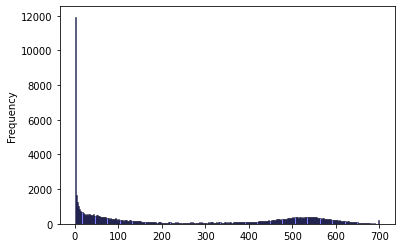

In [67]:
scoring_df_consensus.consensus_score.plot(kind='hist', bins=280, alpha=0.5, color='blue', edgecolor='black')

<Axes: ylabel='Frequency'>

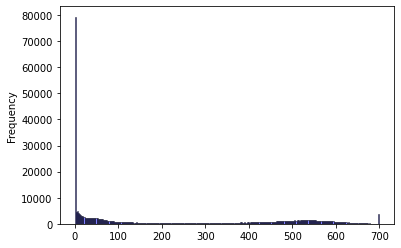

In [68]:
scoring_df.per_well_integrated_intensity_gray.plot(kind='hist', bins=280, alpha=0.5, color='blue', edgecolor='black')

In [69]:
# for group, df in scoring_df_consensus.groupby(['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']):
#     print(group)
#     print(df.per_well_integrated_intensity_gray.values)
#     print(df.consensus_score.values[0])

# Automated clean processing

Number of rows before replacing outliers: 306431
Number of values replaced with NaN: 3057
Percentage of values replaced: 1.00%
Number of rows after replacing outliers: 306431


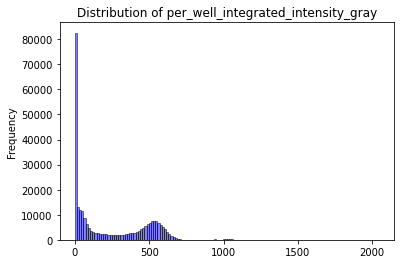

In [70]:
# Load the data from the automated scoring pipeline
auto_df = pd.read_csv(f"{inputs_dir}/sqY2H_manual_automated_annotated_scores.csv")

# both ad_orf_id and db_orf_id must have values (otherwise they are empty wells)
auto_df = auto_df[
    (~auto_df.ad_orf_id.isin(['nan', 'None'])) &
    (~auto_df.db_orf_id.isin(['nan', 'None']))
]

# Remove rows where manual_score_growth is NaN because those wells are flagged as contamination

# do not drop but replace the automatic scores by NA or just add a column for the failling of the manual annotation
# auto_df.dropna(subset=['manual_score_growth'], inplace=True)
auto_df['contamination'] = auto_df['manual_score_growth'].isna()
auto_df

# try to replace per_well_integrated_intensity_gray with NaN if manual_score_growth is NaN
auto_df.loc[auto_df['manual_score_growth'].isna(), 'per_well_integrated_intensity_gray'] = np.nan

# plotting the distribution of per_well_integrated_intensity_gray
auto_df.per_well_integrated_intensity_gray.plot(kind='hist', bins=140, alpha=0.5, color='blue', edgecolor='black', title="Distribution of per_well_integrated_intensity_gray")

# replacing upper bound outliers with NaN because they're caused by misaligned wells
auto_full = auto_df.copy()

# Counting the number of values replaced with NaN
outlier_mask = auto_df.per_well_integrated_intensity_gray >= 750
num_outliers = outlier_mask.sum()

print(f"Number of rows before replacing outliers: {len(auto_df)}")
auto_df.loc[outlier_mask, 'per_well_integrated_intensity_gray'] = np.nan
print(f"Number of values replaced with NaN: {num_outliers}")
print(f"Percentage of values replaced: {(num_outliers / len(auto_df)) * 100:.2f}%")
print(f"Number of rows after replacing outliers: {len(auto_df)}")

<Axes: title={'center': 'Distribution of per_well_integrated_intensity_gray'}, ylabel='Frequency'>

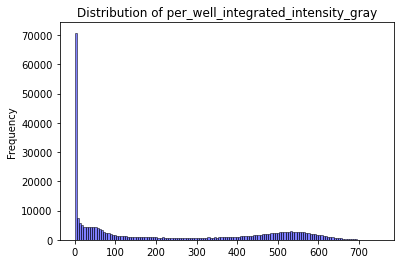

In [71]:
auto_df.per_well_integrated_intensity_gray.plot(kind='hist', bins=140, alpha=0.5, color='blue', edgecolor='black', title="Distribution of per_well_integrated_intensity_gray")


In [72]:
# get media control thresholds
media_score_thresholds = pd.read_csv(f"{inputs_dir}/media_control_score_thresholds.csv")
media_score_thresholds.rename(columns={'control_96': 'scoring_pos'}, inplace=True)

# Split into media controls
media_ctrls = auto_df[auto_df['media_control'] == True]
# auto_df = auto_df[~auto_df['media_control']]

# Check media controls
media_ctrls = media_ctrls[['db_orf_id', 'condition_name', 'retest_batch', 'per_well_integrated_intensity_gray']]
media_ctrls[['scoring_pos', 'retest_pla']] = media_ctrls['db_orf_id'].str.split('_', n=1, expand=True)
media_ctrls = media_ctrls.merge(media_score_thresholds, on=['scoring_pos', 'condition_name'])
media_ctrls

,db_orf_id,condition_name,retest_batch,per_well_integrated_intensity_gray,scoring_pos,retest_pla,control_384,lower_bound,upper_bound
0,A01_1,LW,VUSAPWT1B1,490.572572,A01,1,A01_A02_B01_B02,4,4
1,A01_1,LW,VUSAPWT1B1,521.929437,A01,1,A01_A02_B01_B02,4,4
2,A01_1,LW,VUSAPWT1B1,549.292837,A01,1,A01_A02_B01_B02,4,4
3,A01_1,LW,VUSAPWT1B1,477.786949,A01,1,A01_A02_B01_B02,4,4
4,B01_1,LW,VUSAPWT1B1,465.789564,B01,1,C01_C02_D01_D02,4,4
...,...,...,...,...,...,...,...,...,...
2392,E01_31,LWH25,VUSAPWT1B1,528.958176,E01,31,I01_I02_J01_J02,3,4
2393,F01_31,LWH25,VUSAPWT1B1,473.044449,F01,31,K01_K02_L01_L02,1,3
2394,F01_31,LWH25,VUSAPWT1B1,223.918957,F01,31,K01_K02_L01_L02,1,3
2395,F01_31,LWH25,VUSAPWT1B1,488.665364,F01,31,K01_K02_L01_L02,1,3


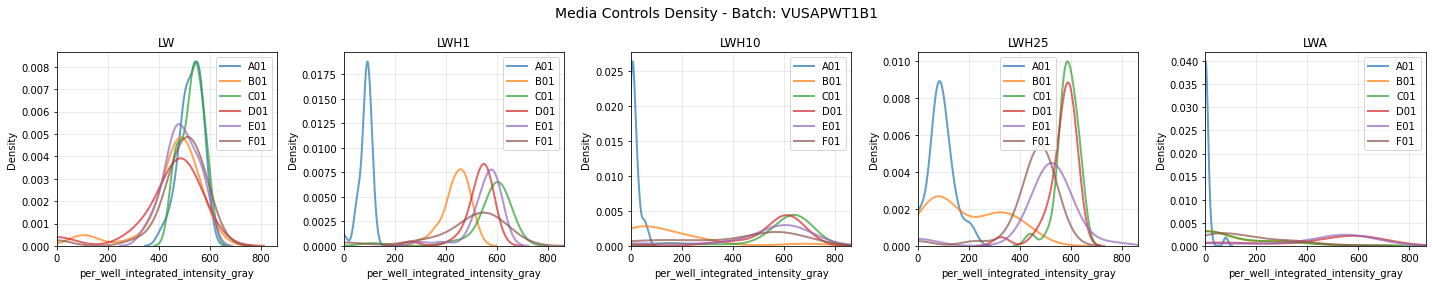

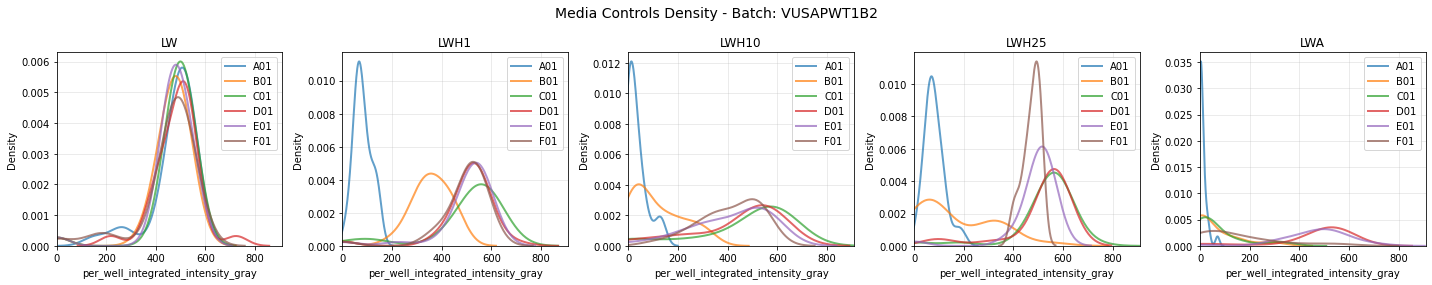

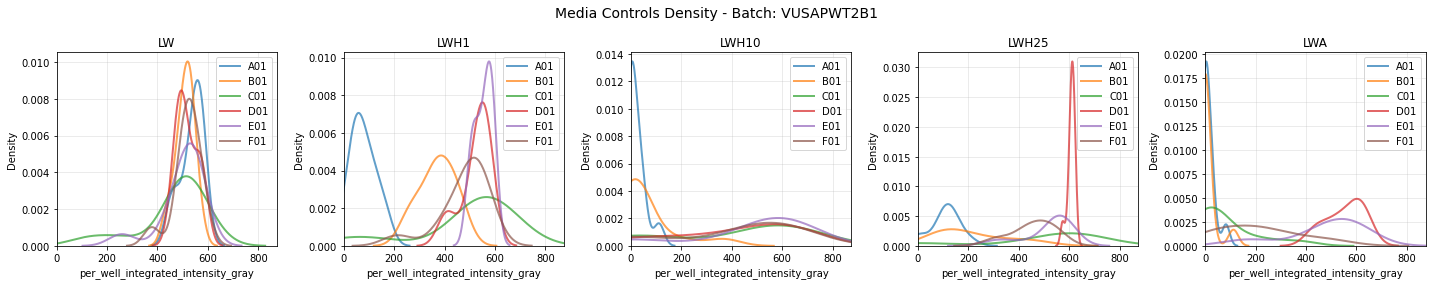

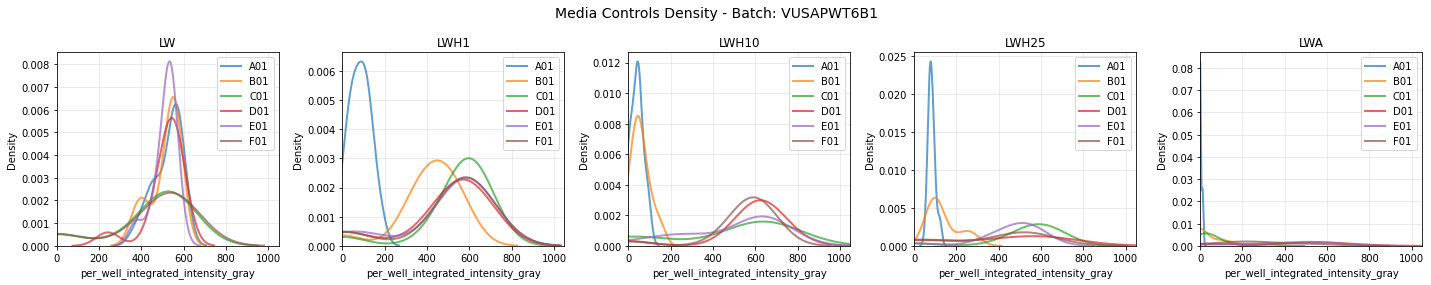

In [73]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Get unique retest_batches and condition_names
retest_batches = media_ctrls['retest_batch'].unique()
condition_names = media_ctrls['condition_name'].unique()
condition_names = ['LW', 'LWH1', 'LWH10', 'LWH25', 'LWA']

for batch in retest_batches:
    # Filter data for this batch
    batch_data = media_ctrls[media_ctrls['retest_batch'] == batch]
    
    # Create subplots - one for each condition
    n_conditions = len(condition_names)
    fig, axes = plt.subplots(1, n_conditions, figsize=(4*n_conditions, 4), sharex=True)
    
    # Handle case where there's only one condition
    if n_conditions == 1:
        axes = [axes]
    
    fig.suptitle(f'Media Controls Density - Batch: {batch}', fontsize=14)
    
    for i, condition in enumerate(condition_names):
        ax = axes[i]
        condition_data = batch_data[batch_data['condition_name'] == condition]
        
        if len(condition_data) > 0:
            # Get unique scoring_pos for this condition
            scoring_positions = condition_data['scoring_pos'].unique()
            
            for pos in scoring_positions:
                pos_data = condition_data[condition_data['scoring_pos'] == pos]
                values = pos_data['per_well_integrated_intensity_gray'].values
                
                if len(values) > 0:
                    # Create density curve using seaborn kdeplot
                    sns.kdeplot(x=values, label=f'{pos}', alpha=0.7, linewidth=2, ax=ax)
        
        ax.set_title(f'{condition}')
        ax.set_xlabel('per_well_integrated_intensity_gray')
        ax.set_ylabel('Density')
        ax.set_xlim(left=0)  # Set lower bound of x-axis to 0
        ax.legend()
        ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

In [74]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages

# Get unique retest_batches and condition_names
retest_batches = media_ctrls['retest_batch'].unique()
condition_names = ['LW', 'LWH1', 'LWH10', 'LWH25', 'LWA']

# Create a single figure with subplots for all batches and conditions
n_batches = len(retest_batches)
n_conditions = len(condition_names)

# Create PDF file
with PdfPages(f'{outputs_dir}/sqY2H/media_controls_density_plots.pdf') as pdf:
    fig, axes = plt.subplots(n_batches, n_conditions, figsize=(5*n_conditions, 4*n_batches), sharex=True)#, sharey=True)
    
    # Handle case where there's only one batch
    if n_batches == 1:
        axes = axes.reshape(1, -1)
    # Handle case where there's only one condition
    if n_conditions == 1:
        axes = axes.reshape(-1, 1)
    
    fig.suptitle('Media Controls Density Plots - All Batches', fontsize=16)
    
    for batch_idx, batch in enumerate(retest_batches):
        # Filter data for this batch
        batch_data = media_ctrls[media_ctrls['retest_batch'] == batch]
        
        for condition_idx, condition in enumerate(condition_names):
            ax = axes[batch_idx, condition_idx]
            condition_data = batch_data[batch_data['condition_name'] == condition]
            
            if len(condition_data) > 0:
                # Get unique scoring_pos for this condition
                scoring_positions = condition_data['scoring_pos'].unique()
                
                for pos in scoring_positions:
                    pos_data = condition_data[condition_data['scoring_pos'] == pos]
                    values = pos_data['per_well_integrated_intensity_gray'].values
                    
                    if len(values) > 0:
                        # Create density curve using seaborn kdeplot
                        sns.kdeplot(x=values, label=f'{pos}', alpha=0.7, linewidth=2, ax=ax)
            
            # Set titles and labels
            if batch_idx == 0:
                ax.set_title(f'{condition}', fontsize=12)
            if condition_idx == 0:
                ax.set_ylabel(f'Batch {batch}\nDensity', fontsize=10)
            if batch_idx == n_batches - 1:
                ax.set_xlabel('per_well_integrated_intensity_gray', fontsize=10)
            
            ax.set_xlim(left=0)
            ax.legend(fontsize=8)
            ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    pdf.savefig(fig, bbox_inches='tight')
    plt.close()

print("PDF saved as 'media_controls_density_plots.pdf'")

PDF saved as 'media_controls_density_plots.pdf'


In [75]:
auto_df

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,contamination
0,VUSAPWT1B1r01_001,A01,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,True,A01_1,NaN,A01_1,NaN,DB_hap_ctrl,A10,AD_hap_ctrl,A10,4.0,490.572572,False
1,VUSAPWT1B1r01_001,A02,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,True,A01_1,NaN,A01_1,NaN,DB_hap_ctrl,A10,AD_hap_ctrl,A10,4.0,521.929437,False
2,VUSAPWT1B1r01_001,A03,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,2651.0,0.0,DisWTGDEh02,G09,CEGSint_Y8A1_2_6,A01,4.0,455.656230,False
3,VUSAPWT1B1r01_001,A04,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,2651.0,0.0,DisWTGDEh02,G09,CEGSint_Y8A1_2_6,A01,4.0,544.304600,False
4,VUSAPWT1B1r01_001,A05,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,7215.0,0.0,DisWTGDEh03,E01,CEGSint_Y8A1_2_6,A01,4.0,505.925513,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
306426,VUSAPWT1B1r06_036,P20,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,54308.0,218854.0,VUSMutY8Dh022,H09,CEGSint_Y8A_6,E11,2.0,435.596088,False
306427,VUSAPWT1B1r06_036,P21,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,54308.0,218855.0,VUSMutY8Dh022,B10,CEGSint_Y8A_6,E11,2.0,NaN,False
306428,VUSAPWT1B1r06_036,P22,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,54308.0,218855.0,VUSMutY8Dh022,B10,CEGSint_Y8A_6,E11,2.0,NaN,False
306429,VUSAPWT1B1r06_036,P23,VUSAPWT1B1r06_031_032_033_034_035_036,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True


/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


95th percentile of MADs: 179.3738266281783


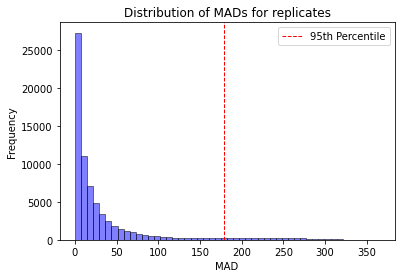

Number of replicates with MAD below 95th percentile: 66674
Total number of replicates: 71706


In [76]:
mads = []

mads_tuples = []

for group, df in auto_df.groupby(['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']):
    scores = df['per_well_integrated_intensity_gray'].dropna().values
    scores_nan = df['per_well_integrated_intensity_gray'].values
    # compute the Median absolute deviation (MAD) of the scores
    median = np.median(scores)
    mean = np.mean(scores)
    mad = np.median(np.abs(scores - median))
    mads.append(mad)
    mads_tuples.append((mad, scores, median, mean))
    # if np.isnan(mad):
        # print(f"Group {group} has NaN MAD with scores: {scores_nan}")

# 95th percentile of MADs, dropping NaNs first
mads_no_nan = [mad for mad in mads if not np.isnan(mad)]
mad_95 = np.percentile(mads_no_nan, 95)
print(f"95th percentile of MADs: {mad_95}")

plt.hist(mads, bins=50, alpha=0.5, color='blue', edgecolor='black')
plt.axvline(mad_95, color='red', linestyle='dashed', linewidth=1, label='95th Percentile')
plt.xlabel('MAD')
plt.ylabel('Frequency')
plt.title('Distribution of MADs for replicates')
plt.legend()
plt.show()

# count the number of replicates with MAD below the 95th percentile
num_below_95 = sum(mad < mad_95 for mad in mads)
print(f"Number of replicates with MAD below 95th percentile: {num_below_95}")
print(f"Total number of replicates: {len(mads)}")


In [77]:
# sorted_mads_tuples = sorted(mads_tuples, key=lambda x: x[0], reverse=True)
# for mad, scores, median, mean in sorted_mads_tuples:
#     print(scores)
#     print(f"MAD: {mad}, Median: {median}, Mean: {mean}")
#     print()

In [78]:
# mads

Number of groups with consensus score: 66018
Number of groups without consensus score: 5688
Total number of groups: 71706
Percentage of groups with consensus score: 92.07%


<Axes: ylabel='Frequency'>

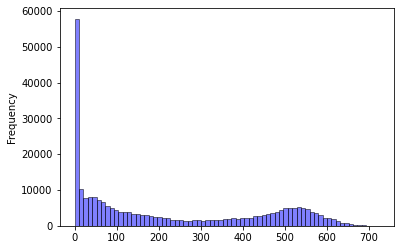

In [79]:
# Compute consensus scores for replicates with MAD below the 95th percentile by taking the mean of the scores and adding it to a new column 'consensus_score'
auto_df['consensus_score'] = np.nan
auto_df['consensus_score'] = auto_df.groupby(
    ['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']
)['per_well_integrated_intensity_gray'].transform(
    lambda x: np.mean(x.dropna()) if len(x.dropna()) > 2 and np.median(np.abs(x.dropna() - np.median(x.dropna()))) < mad_95 else np.nan
)

# Count groups with and without consensus scores more efficiently
consensus_summary = auto_df.groupby(['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch'])['consensus_score'].first().notna()
consensus_count = consensus_summary.sum()
no_consensus_count = len(consensus_summary) - consensus_count

print(f"Number of groups with consensus score: {consensus_count}")
print(f"Number of groups without consensus score: {no_consensus_count}")
print(f"Total number of groups: {len(consensus_summary)}")
print(f"Percentage of groups with consensus score: {consensus_count / len(consensus_summary) * 100:.2f}%")
auto_df['consensus_score'].plot(kind='hist', bins=70, alpha=0.5, color='blue', edgecolor='black')

In [80]:
# for group, df in auto_df.groupby(['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']):
#     print('Replicates', df.per_well_integrated_intensity_gray.values)
#     print('Consensus score', df.consensus_score.values[0])
#     print('---')

In [81]:
# map ad_orf_id to ad_symbol

mapping_file = pd.read_csv(f"{inputs_dir}/cp_files/mapping_y2h.csv")
mapping_file.dropna(subset=['ad_orf_id'], inplace=True)
mapping_dict = mapping_file.set_index('ad_orf_id')['ad_symbol'].to_dict()

# Convert to polars for mapping
auto_df_pl = pl.DataFrame(auto_df)

# Ensure join key types match - cast to string
auto_df_pl = auto_df_pl.with_columns([
    pl.col("db_orf_id").cast(pl.String),
    pl.col("db_mut_id").cast(pl.String)
])

auto_df_pl = auto_df_pl.with_columns(
    pl.col("ad_orf_id").replace_strict(mapping_dict, default=None).alias("ad_symbol")
)

# merge with metadata and write out table
metadata = pl.read_csv(f"{meta_outputs}/slim_metadata.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id"
}).with_columns(
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.String).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.String).alias("db_mut_id")
)

auto_df_pl = auto_df_pl.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")
auto_df_pl.write_csv(f"{outputs_dir}/sqY2H/2_automated_raw_consensus_scores.csv")

# Convert back to pandas if needed
auto_df = auto_df_pl.to_pandas()
auto_df

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
0,VUSAPWT1B1r01_001,A01,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,True,A01_1,NaN,...,None,None,None,None,None,None,None,NaN,NaN,None
1,VUSAPWT1B1r01_001,A02,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,True,A01_1,NaN,...,None,None,None,None,None,None,None,NaN,NaN,None
2,VUSAPWT1B1r01_001,A03,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,empty_ad,CLN6,None,None,ENSG00000128973,None,None,NaN,NaN,CLN6
3,VUSAPWT1B1r01_001,A04,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,empty_ad,CLN6,None,None,ENSG00000128973,None,None,NaN,NaN,CLN6
4,VUSAPWT1B1r01_001,A05,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,empty_ad,NR0B1,None,None,ENSG00000169297,None,None,NaN,NaN,NR0B1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
306426,VUSAPWT1B1r06_036,P20,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,...,SPTA1,PKP2,Phe424Ser,1271T>C,ENSG00000057294,Edgotyping3,4_VUS,NaN,2.0,PKP2_Phe424Ser
306427,VUSAPWT1B1r06_036,P21,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,...,SPTA1,PKP2,Ile487Ser,1460T>G,ENSG00000057294,Edgotyping3,2_Benign,NaN,2.0,PKP2_Ile487Ser
306428,VUSAPWT1B1r06_036,P22,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,...,SPTA1,PKP2,Ile487Ser,1460T>G,ENSG00000057294,Edgotyping3,2_Benign,NaN,2.0,PKP2_Ile487Ser
306429,VUSAPWT1B1r06_036,P23,VUSAPWT1B1r06_031_032_033_034_035_036,None,None,None,NaN,None,None,NaN,...,None,None,None,None,None,None,None,NaN,NaN,None


In [82]:
scoring_df_consensus

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
0,VUSAPWT1B1r01_001,A03,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,empty_ad,CLN6,None,None,ENSG00000128973,None,None,NaN,NaN,CLN6
1,VUSAPWT1B1r01_001,A05,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,empty_ad,NR0B1,None,None,ENSG00000169297,None,None,NaN,NaN,NR0B1
2,VUSAPWT1B1r01_001,A07,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,279.0,NaN,...,CALCOCO2,None,None,None,None,None,None,NaN,NaN,None
3,VUSAPWT1B1r01_001,A09,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,empty_ad,KCNJ2,None,None,ENSG00000123700,None,None,NaN,NaN,KCNJ2
4,VUSAPWT1B1r01_001,A11,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,15066.0,NaN,...,CXorf57,MLH1,None,None,ENSG00000076242,None,None,NaN,NaN,MLH1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71701,VUSAPWT1B1r06_021,A01,VUSAPWT1B1r06_019_020_021_022_023_024,VUSAPWT1B1,r12,LWAH1,1.0,False,0.0,NaN,...,empty_ad,KCNJ2,Val295Ala,884T>C,ENSG00000123700,Edgotyping3,4_VUS,NaN,2.0,KCNJ2_Val295Ala
71702,VUSAPWT1B1r06_021,C01,VUSAPWT1B1r06_019_020_021_022_023_024,VUSAPWT1B1,r12,LWAH1,1.0,False,100016069.0,NaN,...,KCNJ2,KCNJ2,Val295Ala,884T>C,ENSG00000123700,Edgotyping3,4_VUS,NaN,2.0,KCNJ2_Val295Ala
71703,VUSAPWT1B1r06_034,E01,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,4621.0,NaN,...,KXD1,TPM1,Ala239Thr,715G>A,ENSG00000140416,CEGS2,4_VUS,NaN,2.0,TPM1_Ala239Thr
71704,VUSAPWT1B1r06_033,E19,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,12260.0,NaN,...,STX1A,EMD,Met1Val,1A>G,ENSG00000102119,CEGS2,1_Pathogenic,9.500010e-07,2.0,EMD_Met1Val


In [83]:
consensus_scores

ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,condition_name,retest_batch,media_control,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
str,str,str,str,str,str,bool,f64,str,str,str,str,str,str,str,f64,f64,str
"""0.0""","""nan""","""3192.0""","""999999.0""","""LWH25""","""VUSAPWT1B1""",false,2.0,"""empty_ad""",null,null,null,null,null,null,null,null,null
"""4695.0""","""nan""","""13554.0""","""0.0""","""LWAH1""","""VUSAPWT2B1""",false,2.0,"""SMUG1""","""GLYCTK""",null,null,"""ENSG00000168237""",null,null,null,null,"""GLYCTK"""
"""11256.0""","""nan""","""386.0""","""0.0""","""LWH10""","""VUSAPWT1B2""",false,2.0,"""RABEP1""","""STAR""",null,null,"""ENSG00000147465""",null,null,null,null,"""STAR"""
"""14404.0""","""nan""","""2713.0""","""1005.0""","""LWH1""","""VUSAPWT6B1""",false,0.0,"""SPATA8""","""MLH1""","""Gln701His""","""2103G>C""","""ENSG00000076242""","""Edgotyping3""","""1_Pathogenic""",null,3.0,"""MLH1_Gln701His"""
"""4146.0""","""nan""","""2713.0""","""200818.0""","""LWH25""","""VUSAPWT6B1""",false,0.0,"""NELFA""","""MLH1""","""Leu73Arg""","""218T>G""","""ENSG00000076242""","""CEGS2""","""1_Pathogenic""",null,2.0,"""MLH1_Leu73Arg"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""8186.0""","""nan""","""4062.0""","""201422.0""","""LW""","""VUSAPWT2B1""",false,4.0,"""CLEC2D""","""PLP1""","""Thr43Ile""","""128C>T""","""ENSG00000123560""","""CEGS2""","""1_Pathogenic""",null,1.0,"""PLP1_Thr43Ile"""
"""54341.0""","""nan""","""2713.0""","""200850.0""","""LWAH1""","""VUSAPWT1B1""",false,99999.0,"""PTPN3""","""MLH1""","""Ser295Thr""","""884G>C""","""ENSG00000076242""","""CEGS2""","""4_VUS""",null,3.0,"""MLH1_Ser295Thr"""
"""54668.0""","""nan""","""70497.0""","""3851.0""","""LWH10""","""VUSAPWT1B1""",false,2.0,"""KRT40""","""AGXT""","""Ser221Pro""","""661T>C""","""ENSG00000172482""","""Edgotyping3""","""1_Pathogenic""",null,null,"""AGXT_Ser221Pro"""


In [84]:
autotest_df = auto_df.drop_duplicates(subset=['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch'])
autotest_df

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
0,VUSAPWT1B1r01_001,A01,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,True,A01_1,NaN,...,None,None,None,None,None,None,None,NaN,NaN,None
2,VUSAPWT1B1r01_001,A03,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,empty_ad,CLN6,None,None,ENSG00000128973,None,None,NaN,NaN,CLN6
4,VUSAPWT1B1r01_001,A05,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,empty_ad,NR0B1,None,None,ENSG00000169297,None,None,NaN,NaN,NR0B1
6,VUSAPWT1B1r01_001,A07,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,279.0,NaN,...,CALCOCO2,None,None,None,None,None,None,NaN,NaN,None
8,VUSAPWT1B1r01_001,A09,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,empty_ad,KCNJ2,None,None,ENSG00000123700,None,None,NaN,NaN,KCNJ2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
306371,VUSAPWT1B1r06_036,O13,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100063955.0,NaN,...,N4BP1,LITAF,Leu122Val,364C>G,ENSG00000189067,Edgotyping3,1_Pathogenic,NaN,NaN,LITAF_Leu122Val
306373,VUSAPWT1B1r06_036,O15,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,3598.0,NaN,...,DAZAP2,LITAF,Leu122Val,364C>G,ENSG00000189067,Edgotyping3,1_Pathogenic,NaN,NaN,LITAF_Leu122Val
306375,VUSAPWT1B1r06_036,O17,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,53212.0,NaN,...,ROPN1,PKP2,Ala372Pro,1114G>C,ENSG00000057294,Edgotyping3,3_Conflicting,NaN,1.0,PKP2_Ala372Pro
306377,VUSAPWT1B1r06_036,O19,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,...,SPTA1,PKP2,Phe424Ser,1271T>C,ENSG00000057294,Edgotyping3,4_VUS,NaN,2.0,PKP2_Phe424Ser


In [85]:
# Compare the three consensus scoring methods
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import pearsonr, spearmanr

# Get the three datasets with consensus scores
manual_df = consensus_scores.to_pandas()
mode_automated_df = scoring_df_consensus
mad_automated_df = autotest_df

print("Dataset shapes:")
print(f"Manual: {manual_df.shape}")
print(f"Mode-based automated: {mode_automated_df.shape}")
print(f"MAD-based automated: {mad_automated_df.shape}")

# Create a common merge key for comparison
def create_merge_key(df):
    return df['ad_orf_id'].astype(str) + '_' + df['db_orf_id'].astype(str) + '_' + df['db_mut_id'].astype(str) + '_' + df['condition_name'] + '_' + df['retest_batch']

manual_df['merge_key'] = create_merge_key(manual_df)
mode_automated_df['merge_key'] = create_merge_key(mode_automated_df)
mad_automated_df['merge_key'] = create_merge_key(mad_automated_df)

# Merge all three datasets
comparison_df = manual_df[['merge_key', 'consensus_score']].rename(columns={'consensus_score': 'manual_score'})
comparison_df = comparison_df.merge(
    mode_automated_df[['merge_key', 'consensus_score']].rename(columns={'consensus_score': 'mode_score'}),
    on='merge_key', how='outer'
)
comparison_df = comparison_df.merge(
    mad_automated_df[['merge_key', 'consensus_score']].rename(columns={'consensus_score': 'mad_score'}),
    on='merge_key', how='outer'
)

print(f"\nMerged comparison dataset shape: {comparison_df.shape}")
print(f"Records with all three scores: {comparison_df.dropna().shape[0]}")
print(f"Records with manual + mode: {comparison_df[['manual_score', 'mode_score']].dropna().shape[0]}")
print(f"Records with manual + MAD: {comparison_df[['manual_score', 'mad_score']].dropna().shape[0]}")
print(f"Records with mode + MAD: {comparison_df[['mode_score', 'mad_score']].dropna().shape[0]}")

comparison_df

Dataset shapes:
Manual: (72210, 18)
Mode-based automated: (71706, 30)
MAD-based automated: (72211, 30)

Merged comparison dataset shape: (72715, 4)
Records with all three scores: 64729
Records with manual + mode: 68240
Records with manual + MAD: 66018
Records with mode + MAD: 64729


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_46272/4290429483.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mad_automated_df['merge_key'] = create_merge_key(mad_automated_df)


,merge_key,manual_score,mode_score,mad_score
0,0.0_100000400.0_0.0_LWAH1_VUSAPWT1B2,0.0,0.000000,0.000000
1,0.0_100000400.0_0.0_LWA_VUSAPWT1B2,0.0,3.022222,3.022222
2,0.0_100000400.0_0.0_LWH10_VUSAPWT1B2,0.0,11.587909,11.587909
3,0.0_100000400.0_0.0_LWH1_VUSAPWT1B2,0.0,78.772877,78.772877
4,0.0_100000400.0_0.0_LWH25_VUSAPWT1B2,0.0,52.801635,52.801635
...,...,...,...,...
72710,F01_7_F01_7_nan_LWH25_VUSAPWT1B1,4.0,NaN,NaN
72711,F01_7_F01_7_nan_LWH25_VUSAPWT1B2,3.0,NaN,NaN
72712,F01_7_F01_7_nan_LW_VUSAPWT1B1,4.0,NaN,NaN
72713,F01_7_F01_7_nan_LW_VUSAPWT1B2,4.0,NaN,NaN


In [86]:
cp_df = pd.read_csv('/Users/user_42/Partners HealthCare Dropbox/Maxime Tixhon/PhD/VarChamp/2025_laval_submitted/2_individual_assay_results/ppi/1_inputs/sqY2H/cp_files/mapping_y2h.csv')
cp_df

,retest_id,ad_orf_id,ad_symbol,ad_mut_id,db_orf_id,db_symbol,db_mut_id,retest_pla,retest_pos,retest_batch,standard_batch,assay_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well
0,49123,NaN,ad_control_1,NaN,NaN,db_control_1,NaN,1,A01,VUSAPWT1B1,VUSAPWT1B1,1,DB_hap_ctrl,A10,AD_hap_ctrl,A10
1,49124,NaN,ad_control_1,NaN,NaN,db_control_1,NaN,7,A01,VUSAPWT1B1,VUSAPWT1B1,1,DB_hap_ctrl,A10,AD_hap_ctrl,A10
2,49125,NaN,ad_control_1,NaN,NaN,db_control_1,NaN,13,A01,VUSAPWT1B1,VUSAPWT1B1,1,DB_hap_ctrl,A10,AD_hap_ctrl,A10
3,49126,NaN,ad_control_1,NaN,NaN,db_control_1,NaN,19,A01,VUSAPWT1B1,VUSAPWT1B1,1,DB_hap_ctrl,A10,AD_hap_ctrl,A10
4,49127,NaN,ad_control_1,NaN,NaN,db_control_1,NaN,25,A01,VUSAPWT1B1,VUSAPWT1B1,1,DB_hap_ctrl,A10,AD_hap_ctrl,A10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12582,73082,0.0,empty_ad,NaN,4527.0,BYSL,NaN,8,G11,VUSPRSRRS,VUSPRSRRS,1,db_2A_RRS,G11,empty_ad_plate,G11
12583,73083,0.0,empty_ad,NaN,2794.0,HBA2,NaN,8,H11,VUSPRSRRS,VUSPRSRRS,1,db_2A_PRS,H11,empty_ad_plate,H11
12584,73084,0.0,empty_ad,NaN,2403.0,ORC2,NaN,8,A12,VUSPRSRRS,VUSPRSRRS,1,db_2A_PRS,A12,empty_ad_plate,A12
12585,73085,0.0,empty_ad,NaN,3341.0,CKB,NaN,8,B12,VUSPRSRRS,VUSPRSRRS,1,db_2A_RRS,B12,empty_ad_plate,B12


In [87]:
cp_df[
    (cp_df.retest_batch == 'VUSAPWT6B1') &
    (cp_df.retest_pla == 19) &
    (cp_df.retest_pos == 'C02') 
    
]

,retest_id,ad_orf_id,ad_symbol,ad_mut_id,db_orf_id,db_symbol,db_mut_id,retest_pla,retest_pos,retest_batch,standard_batch,assay_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well
9685,69092,6281.0,KCNJ15,NaN,100016069.0,KCNJ2,2646.0,19,C02,VUSAPWT6B1,VUSAPWT6B1,6,VUSMutY8Dh010,D07,CEGSint_Y8A6_2,A05
